In [1]:
%pip install matplotlib seaborn wordcloud plotly -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 1: Setup and Load All Dataset Files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
import glob
from collections import Counter

# Set up plotting for thesis quality
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 12
sns.set_style("whitegrid")

print("📚 Mental Health Function Calling Dataset - Complete EDA")
print("=" * 55)

# Load ALL JSON files from fc_training_data directory
base_path = "/home/jovyan/Works/MSc_Thesis/mh_function_calling/dataset_generation/fc_training_data"

all_data = []
file_count = 0

# Get all JSON files in the directory
json_files = glob.glob(os.path.join(base_path, "*.json"))

for json_file in json_files:
    try:
        with open(json_file, 'r') as f:
            data = json.load(f)
        
        # Add source file info to each record
        filename = os.path.basename(json_file)
        function_name = filename.replace('_data.json', '').replace('.json', '')
        
        for record in data:
            record['source_file'] = filename
            record['source_function'] = function_name
            all_data.append(record)
        
        print(f"✅ Loaded {filename}: {len(data)} samples")
        file_count += 1
        
    except Exception as e:
        print(f"❌ Error loading {json_file}: {e}")

# Create combined DataFrame
df = pd.DataFrame(all_data)

print(f"\n📊 COMPLETE DATASET LOADED:")
print(f"Files processed: {file_count}")
print(f"Total samples: {len(df):,}")
print(f"Columns: {list(df.columns)}")
print(f"Shape: {df.shape}")

📚 Mental Health Function Calling Dataset - Complete EDA
✅ Loaded blood_glucose_data.json: 251 samples
✅ Loaded weight_data.json: 253 samples
✅ Loaded sleep_data.json: 251 samples
✅ Loaded height_data.json: 253 samples
✅ Loaded exercise_session_data.json: 251 samples
✅ Loaded blood_pressure_data.json: 251 samples
✅ Loaded exercise_heart_rate_data.json: 256 samples
✅ Loaded speed_data.json: 259 samples
✅ Loaded power_data.json: 256 samples
✅ Loaded distance_data.json: 251 samples
✅ Loaded steps_data.json: 276 samples
✅ Loaded bmr_data.json: 256 samples
✅ Loaded body_temp_data.json: 251 samples
✅ Loaded body_fat_data.json: 254 samples
✅ Loaded oxygen_saturation_data.json: 259 samples
✅ Loaded stress_data.json: 254 samples
✅ Loaded nutrition_data.json: 251 samples
✅ Loaded vo2max_data.json: 254 samples
✅ Loaded calories_burned_data.json: 253 samples
✅ Loaded heart_rate_data.json: 259 samples

📊 COMPLETE DATASET LOADED:
Files processed: 20
Total samples: 5,099
Columns: ['query', 'type', 'th

In [3]:
# Cell 2: Dataset Structure and Completeness
print("📊 DATASET OVERVIEW")
print("-" * 30)

print(f"Total samples: {len(df):,}")
print(f"Total features: {len(df.columns)}")
print(f"Unique functions: {df['source_function'].nunique()}")

# Check data completeness
print(f"\n📋 DATA COMPLETENESS:")
print("-" * 25)
for col in df.columns:
    missing = df[col].isnull().sum()
    complete = len(df) - missing
    percentage = (complete / len(df)) * 100
    print(f"  {col}: {complete}/{len(df)} ({percentage:.1f}%)")

# Show unique functions
print(f"\n🔧 FUNCTIONS IN DATASET:")
print("-" * 25)
function_counts = df['source_function'].value_counts()
for func, count in function_counts.items():
    print(f"  {func}: {count} samples")

print(f"\n🔍 SAMPLE STRUCTURE:")
print("-" * 20)
print("First complete sample:")
print(df.iloc[0].to_dict())

📊 DATASET OVERVIEW
------------------------------
Total samples: 5,099
Total features: 7
Unique functions: 20

📋 DATA COMPLETENESS:
-------------------------
  query: 5099/5099 (100.0%)
  type: 5099/5099 (100.0%)
  thinking: 5099/5099 (100.0%)
  numdays: 5071/5099 (99.5%)
  function: 5099/5099 (100.0%)
  source_file: 5099/5099 (100.0%)
  source_function: 5099/5099 (100.0%)

🔧 FUNCTIONS IN DATASET:
-------------------------
  steps: 276 samples
  oxygen_saturation: 259 samples
  speed: 259 samples
  heart_rate: 259 samples
  bmr: 256 samples
  exercise_heart_rate: 256 samples
  power: 256 samples
  stress: 254 samples
  vo2max: 254 samples
  body_fat: 254 samples
  height: 253 samples
  weight: 253 samples
  calories_burned: 253 samples
  blood_glucose: 251 samples
  sleep: 251 samples
  blood_pressure: 251 samples
  distance: 251 samples
  exercise_session: 251 samples
  body_temp: 251 samples
  nutrition: 251 samples

🔍 SAMPLE STRUCTURE:
--------------------
First complete sample:
{'q

In [6]:
# 2. Basic Statistics and Data Quality
# ====================================

print("📈 BASIC STATISTICS")
print("-" * 30)

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Basic stats for numerical columns
print(f"\nNum_days statistics:")
print(df['num_days'].describe())

# Unique values
print(f"\nUnique functions: {df['function_name'].nunique()}")
print(f"Unique patient IDs: {df['patient_id'].nunique()}")
print(f"Unique num_days values: {sorted(df['num_days'].unique())}")

# Data quality checks
print(f"\nData Quality Checks:")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Empty queries: {df['patient_query'].str.strip().eq('').sum()}")
print(f"Empty responses: {df['assistant_response'].str.strip().eq('').sum()}")

📈 BASIC STATISTICS
------------------------------
Missing values:
patient_query         0
assistant_response    0
function_name         0
patient_id            0
num_days              0
dtype: int64

Num_days statistics:
count    4000.00000
mean       13.41175
std         9.67244
min         1.00000
25%         5.00000
50%        14.00000
75%        21.00000
max        30.00000
Name: num_days, dtype: float64

Unique functions: 20
Unique patient IDs: 888
Unique num_days values: [np.int64(1), np.int64(3), np.int64(5), np.int64(7), np.int64(10), np.int64(14), np.int64(15), np.int64(21), np.int64(28), np.int64(30)]

Data Quality Checks:
Duplicate rows: 2
Empty queries: 0
Empty responses: 0


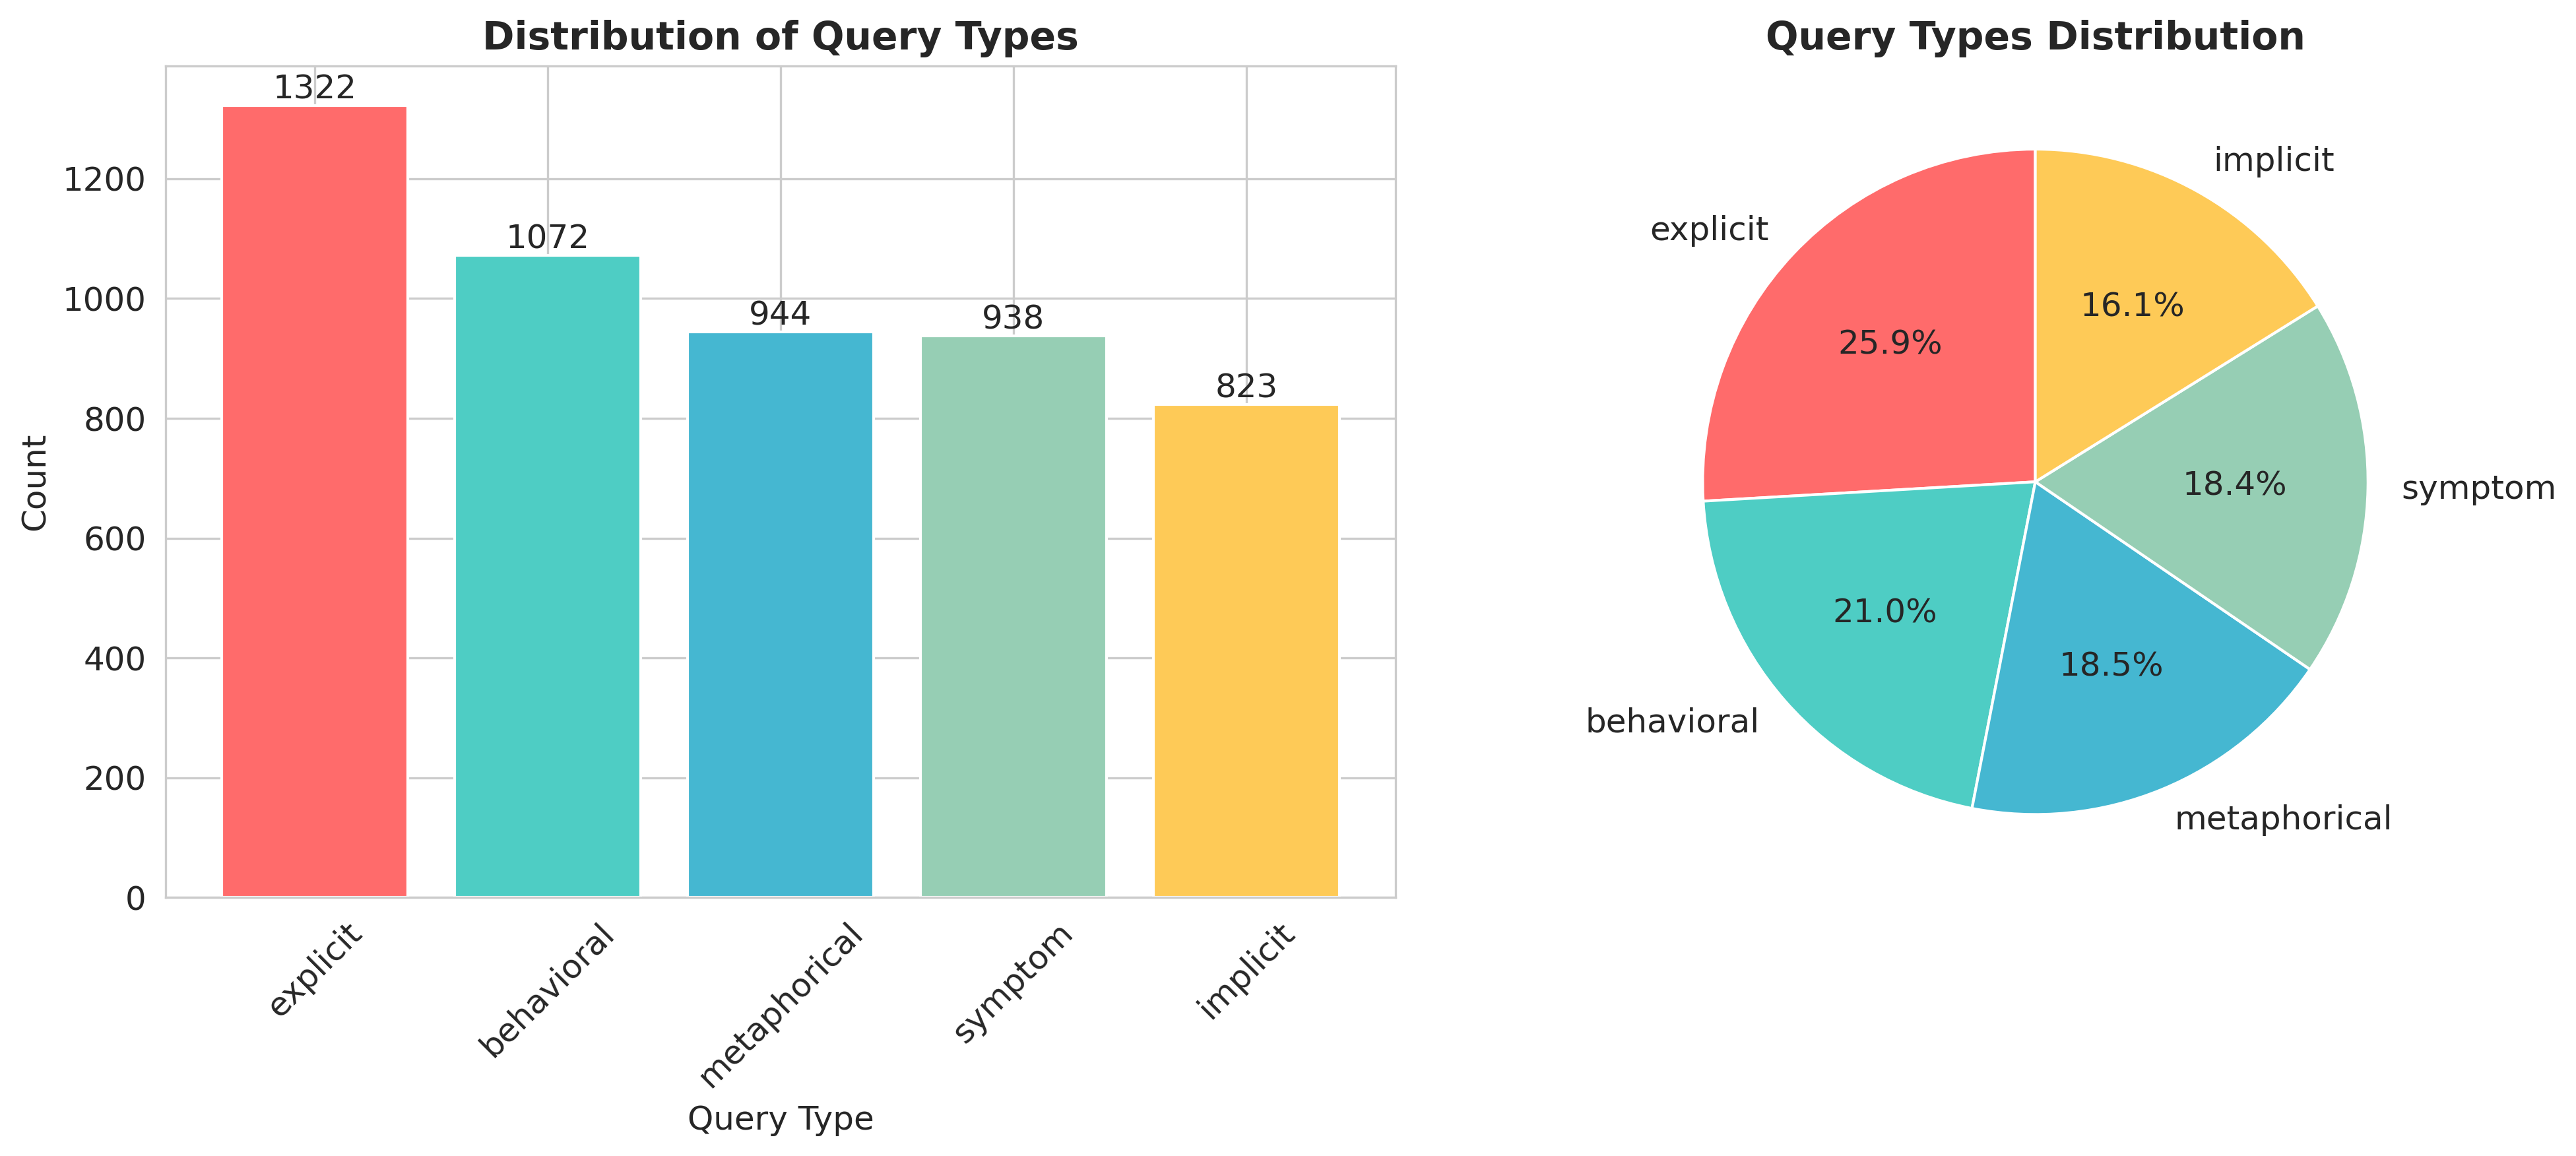

📊 QUERY TYPES SUMMARY:
-------------------------
  Explicit: 1322 samples (25.9%)
  Behavioral: 1072 samples (21.0%)
  Metaphorical: 944 samples (18.5%)
  Symptom: 938 samples (18.4%)
  Implicit: 823 samples (16.1%)


In [16]:
# Cell 3: Query Types Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Type distribution
type_counts = df['type'].value_counts()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57']

# Bar chart
bars = ax1.bar(type_counts.index, type_counts.values, color=colors[:len(type_counts)])
ax1.set_title('Distribution of Query Types', fontweight='bold', fontsize=14)
ax1.set_xlabel('Query Type')
ax1.set_ylabel('Count')
ax1.tick_params(axis='x', rotation=45)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f'{int(height)}', ha='center', va='bottom')

# Pie chart
wedges, texts, autotexts = ax2.pie(type_counts.values, labels=type_counts.index, 
                                   autopct='%1.1f%%', startangle=90, colors=colors[:len(type_counts)])
ax2.set_title('Query Types Distribution', fontweight='bold', fontsize=14)

plt.tight_layout()
plt.show()

print("📊 QUERY TYPES SUMMARY:")
print("-" * 25)
for qtype, count in type_counts.items():
    percentage = (count / len(df)) * 100
    print(f"  {qtype.capitalize()}: {count} samples ({percentage:.1f}%)")

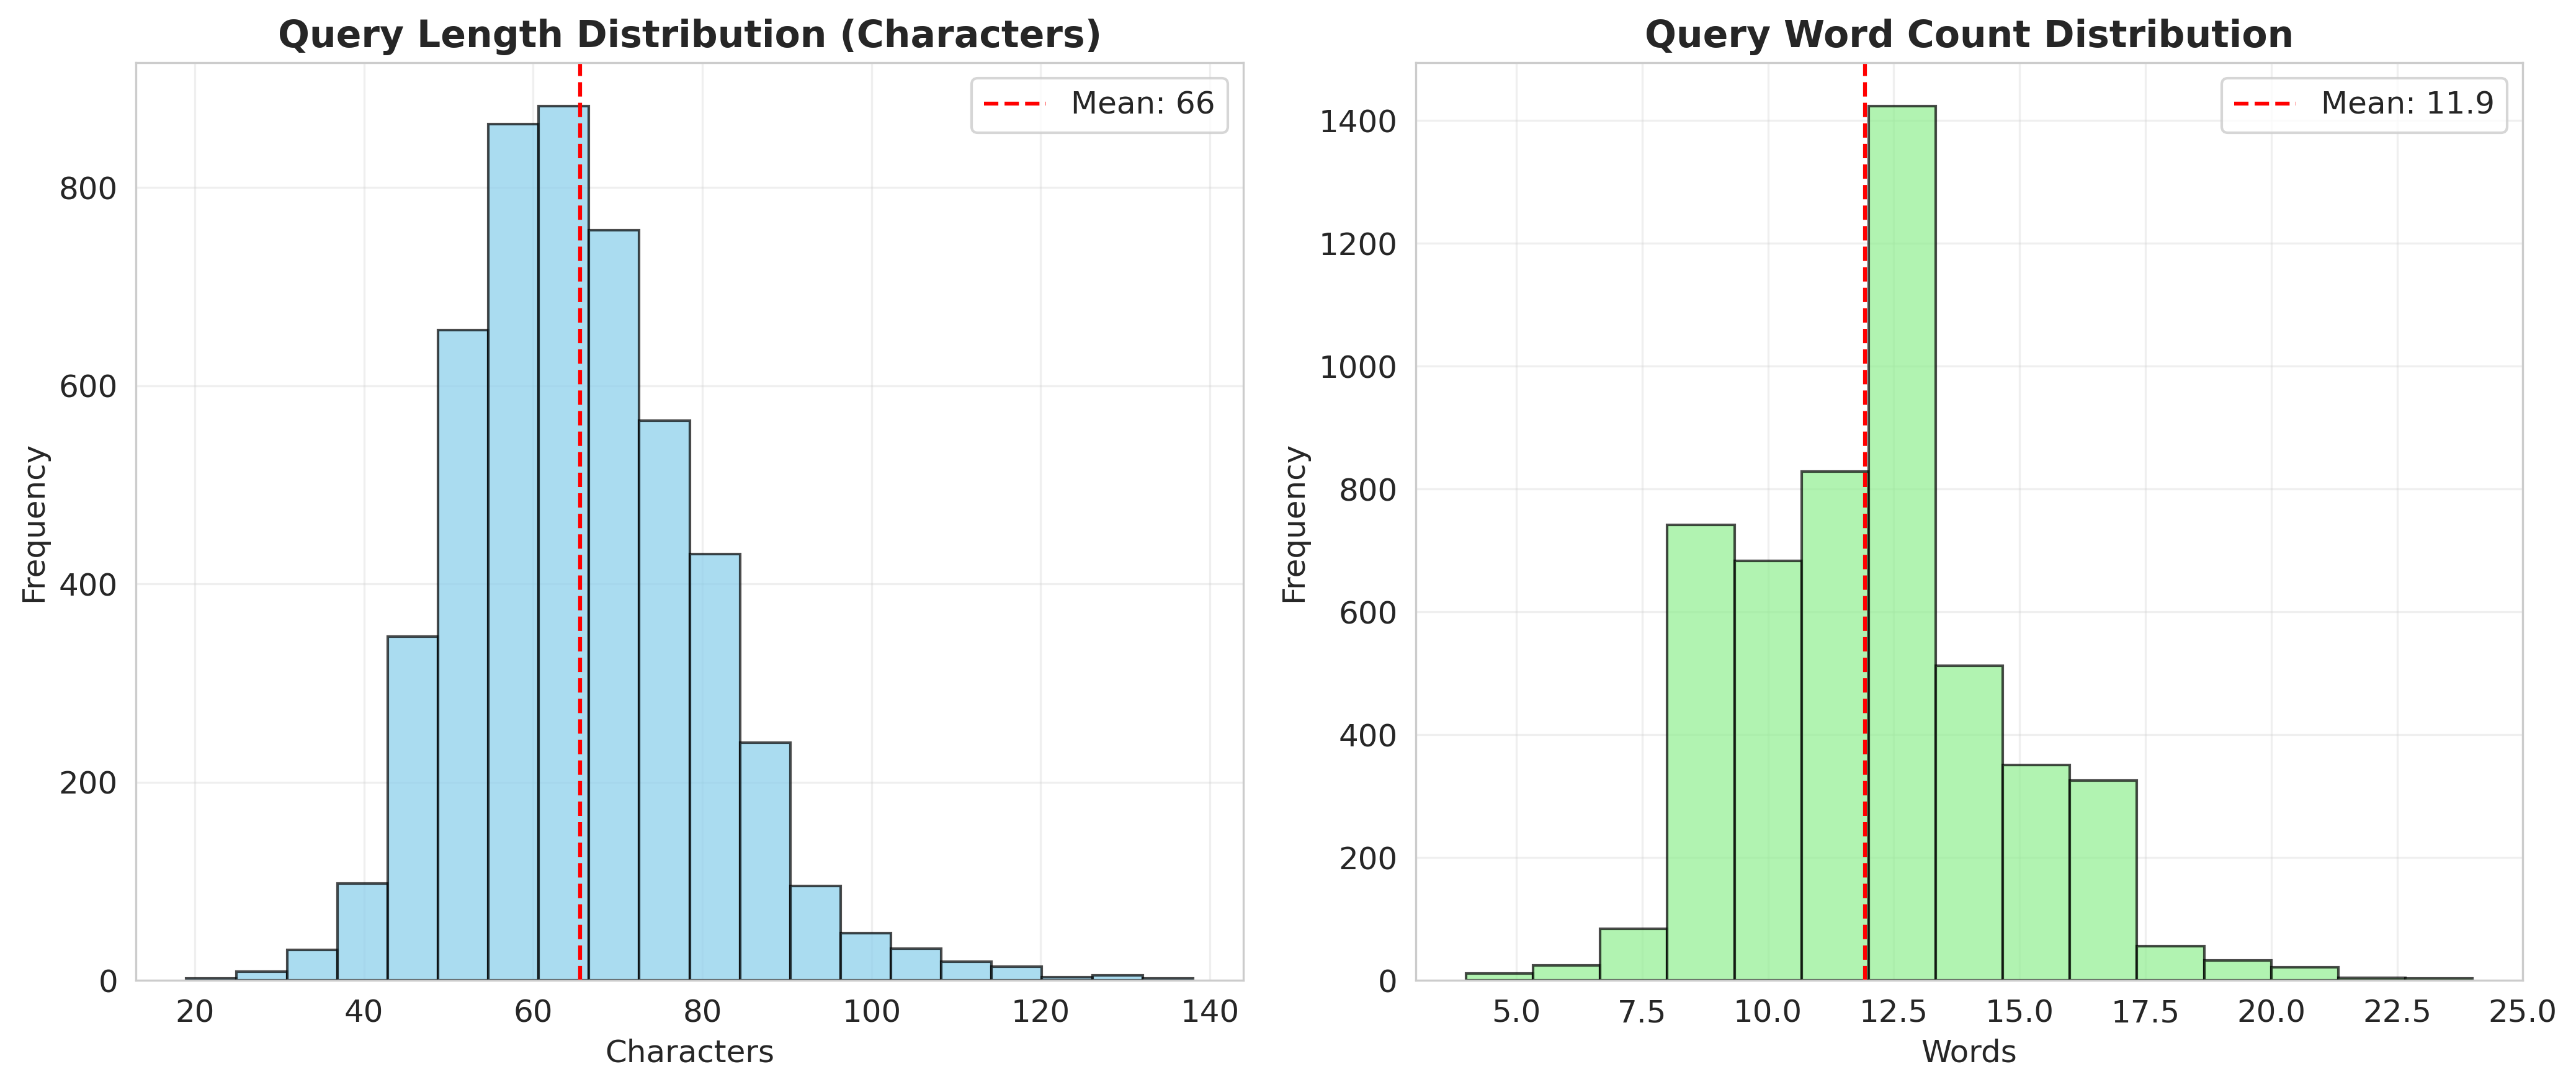

📝 TEXT CHARACTERISTICS:
-------------------------
Average query length: 65.6 characters
Average word count: 11.9 words
Length range: 19 - 138 characters
Word range: 4 - 24 words


In [5]:
# Cell 4: Query Text Characteristics
# Calculate text metrics
df['query_length'] = df['query'].str.len()
df['query_words'] = df['query'].str.split().str.len()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Query length distribution
ax1.hist(df['query_length'], bins=20, color='skyblue', alpha=0.7, edgecolor='black')
ax1.axvline(df['query_length'].mean(), color='red', linestyle='--', 
            label=f'Mean: {df["query_length"].mean():.0f}')
ax1.set_title('Query Length Distribution (Characters)', fontweight='bold')
ax1.set_xlabel('Characters')
ax1.set_ylabel('Frequency')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Word count distribution
ax2.hist(df['query_words'], bins=15, color='lightgreen', alpha=0.7, edgecolor='black')
ax2.axvline(df['query_words'].mean(), color='red', linestyle='--',
            label=f'Mean: {df["query_words"].mean():.1f}')
ax2.set_title('Query Word Count Distribution', fontweight='bold')
ax2.set_xlabel('Words')
ax2.set_ylabel('Frequency')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("📝 TEXT CHARACTERISTICS:")
print("-" * 25)
print(f"Average query length: {df['query_length'].mean():.1f} characters")
print(f"Average word count: {df['query_words'].mean():.1f} words")
print(f"Length range: {df['query_length'].min()} - {df['query_length'].max()} characters")
print(f"Word range: {df['query_words'].min()} - {df['query_words'].max()} words")

🕒 PATIENT TEMPORAL EXPRESSION NUANCES


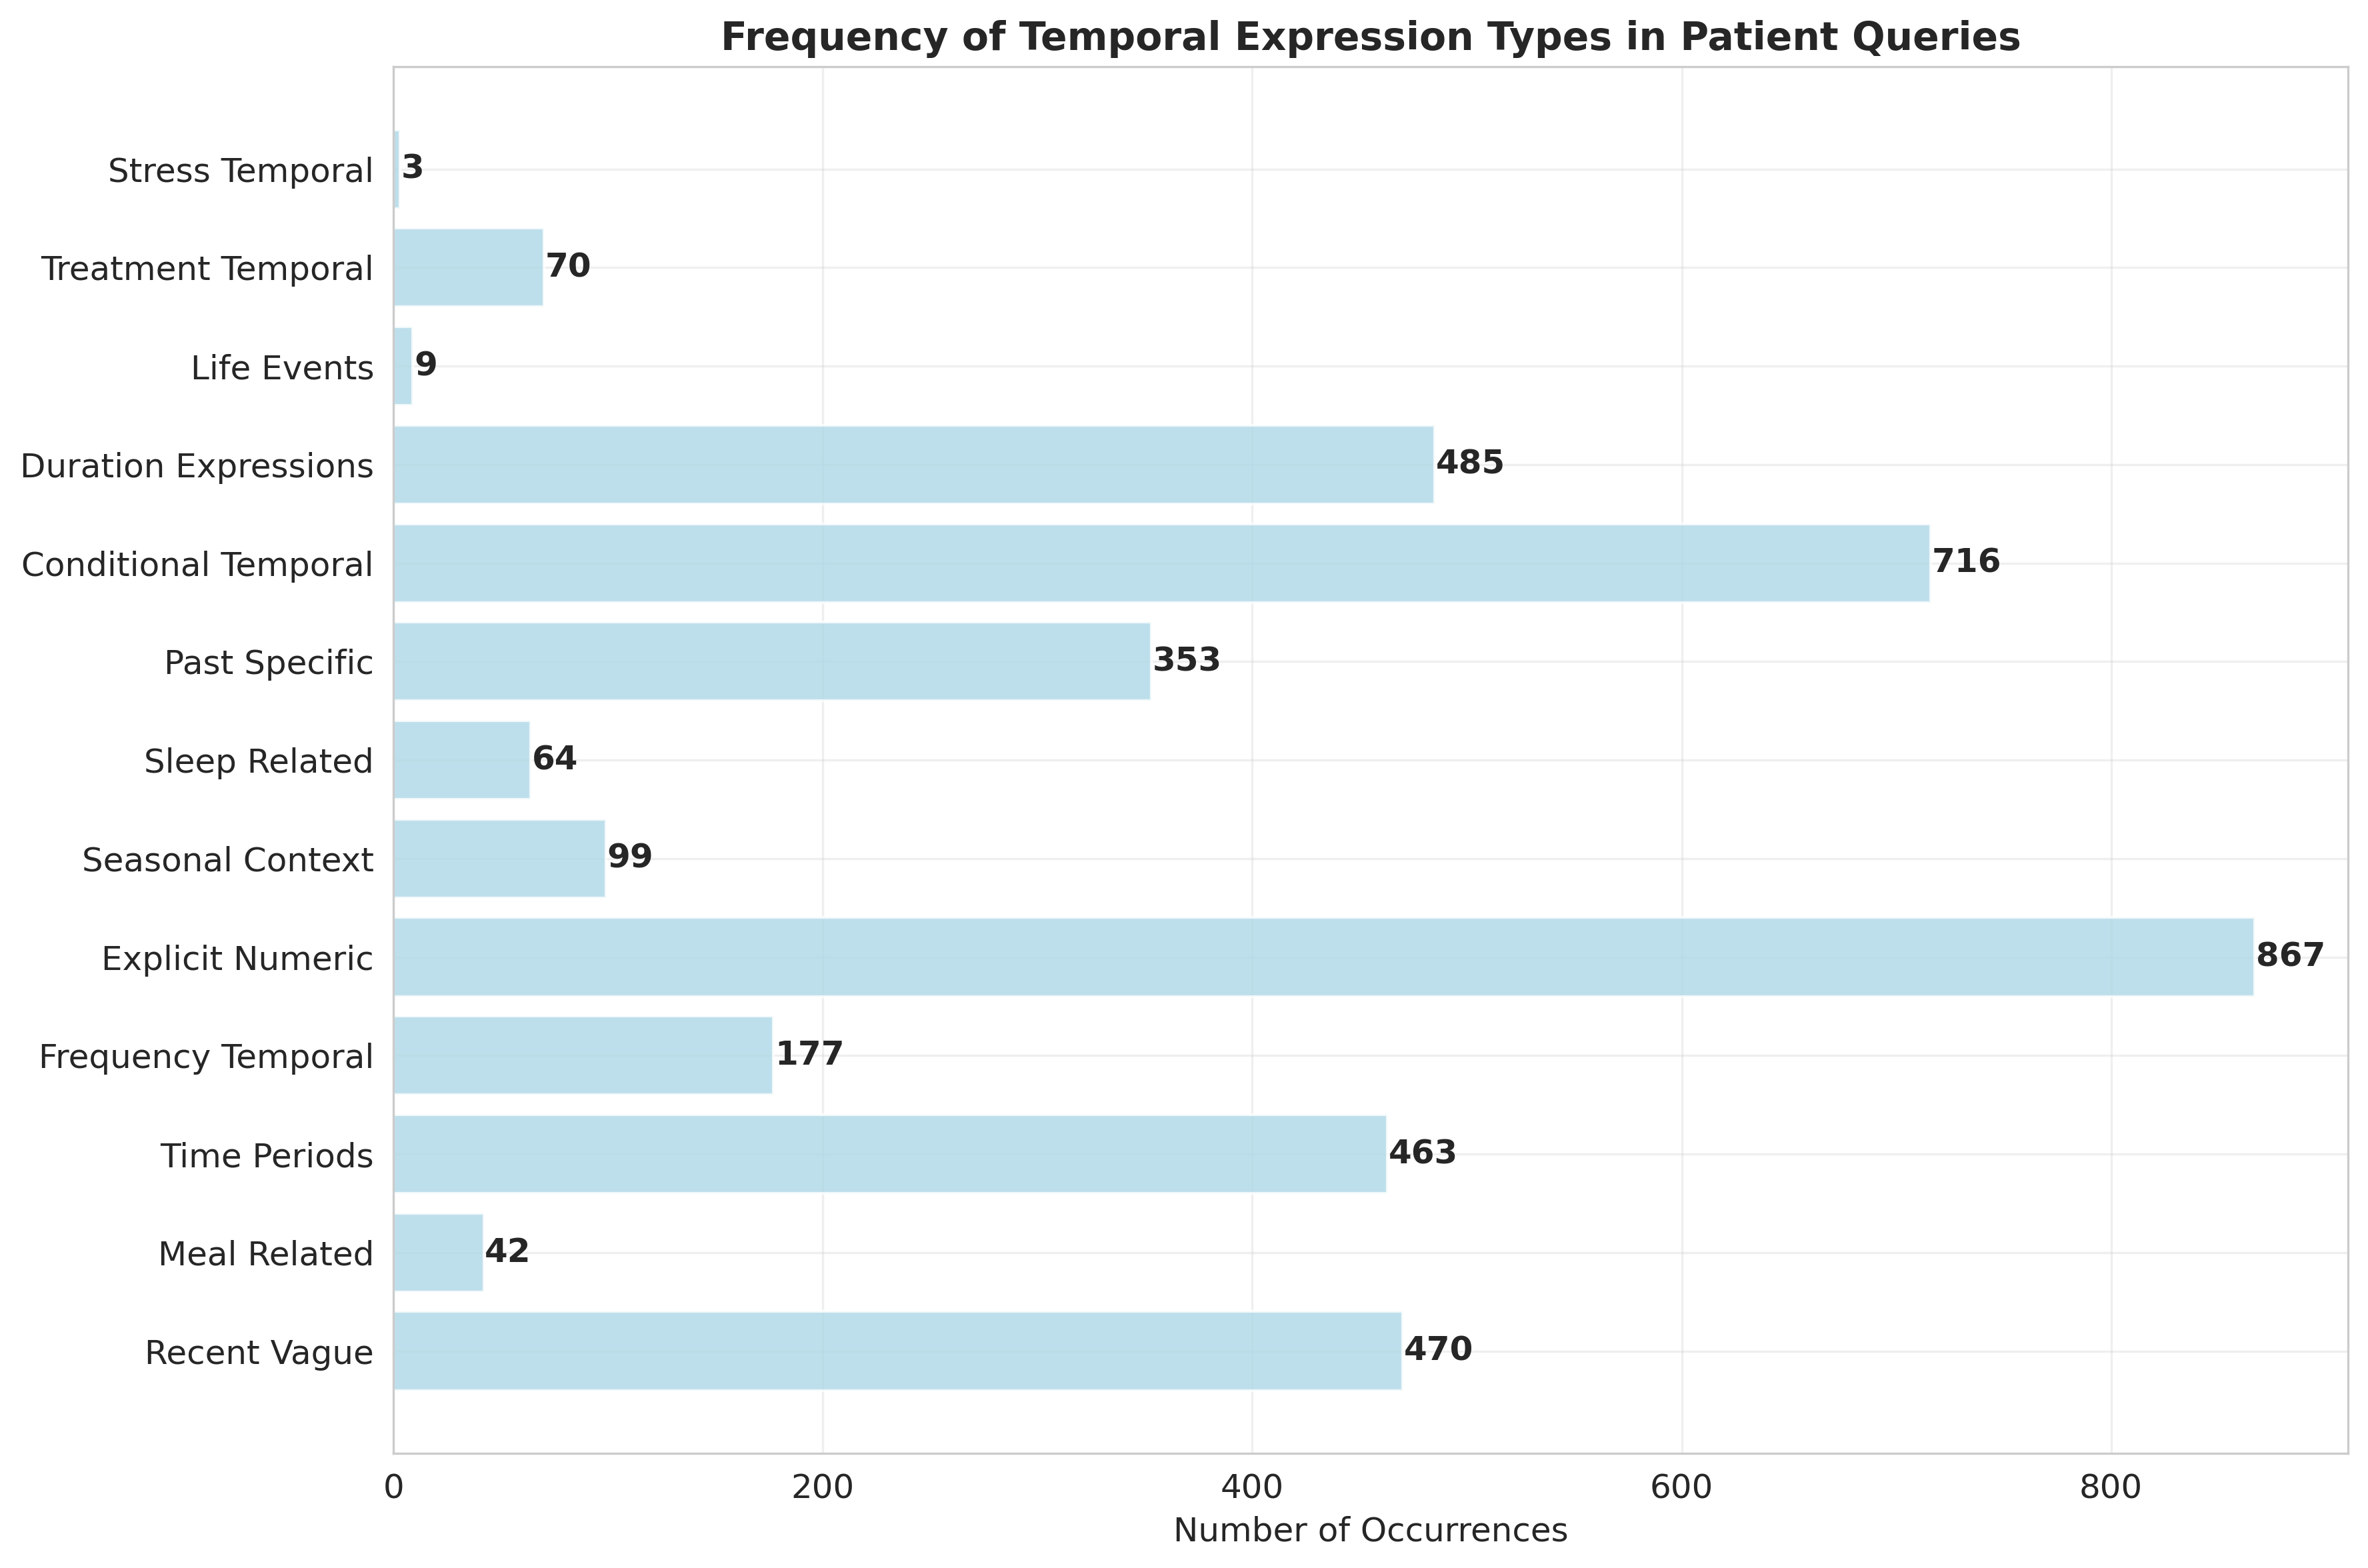

In [17]:
# Cell 6a: Temporal Pattern Frequency (Most Important)
print("🕒 PATIENT TEMPORAL EXPRESSION NUANCES")
print("=" * 50)

# [Keep all the pattern definitions and analysis code from before...]

# Figure 1: Overall Temporal Pattern Usage (Most Important)
plt.figure(figsize=(12, 8))
if pattern_frequency:
    pattern_names = list(pattern_frequency.keys())
    pattern_counts = list(pattern_frequency.values())
    
    # Clean pattern names for display
    clean_names = [name.replace('_', ' ').title() for name in pattern_names]
    
    bars = plt.barh(clean_names, pattern_counts, color='lightblue', alpha=0.8)
    plt.title('Frequency of Temporal Expression Types in Patient Queries', fontweight='bold', fontsize=14)
    plt.xlabel('Number of Occurrences')
    plt.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, count in zip(bars, pattern_counts):
        width = bar.get_width()
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
                f'{count}', ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

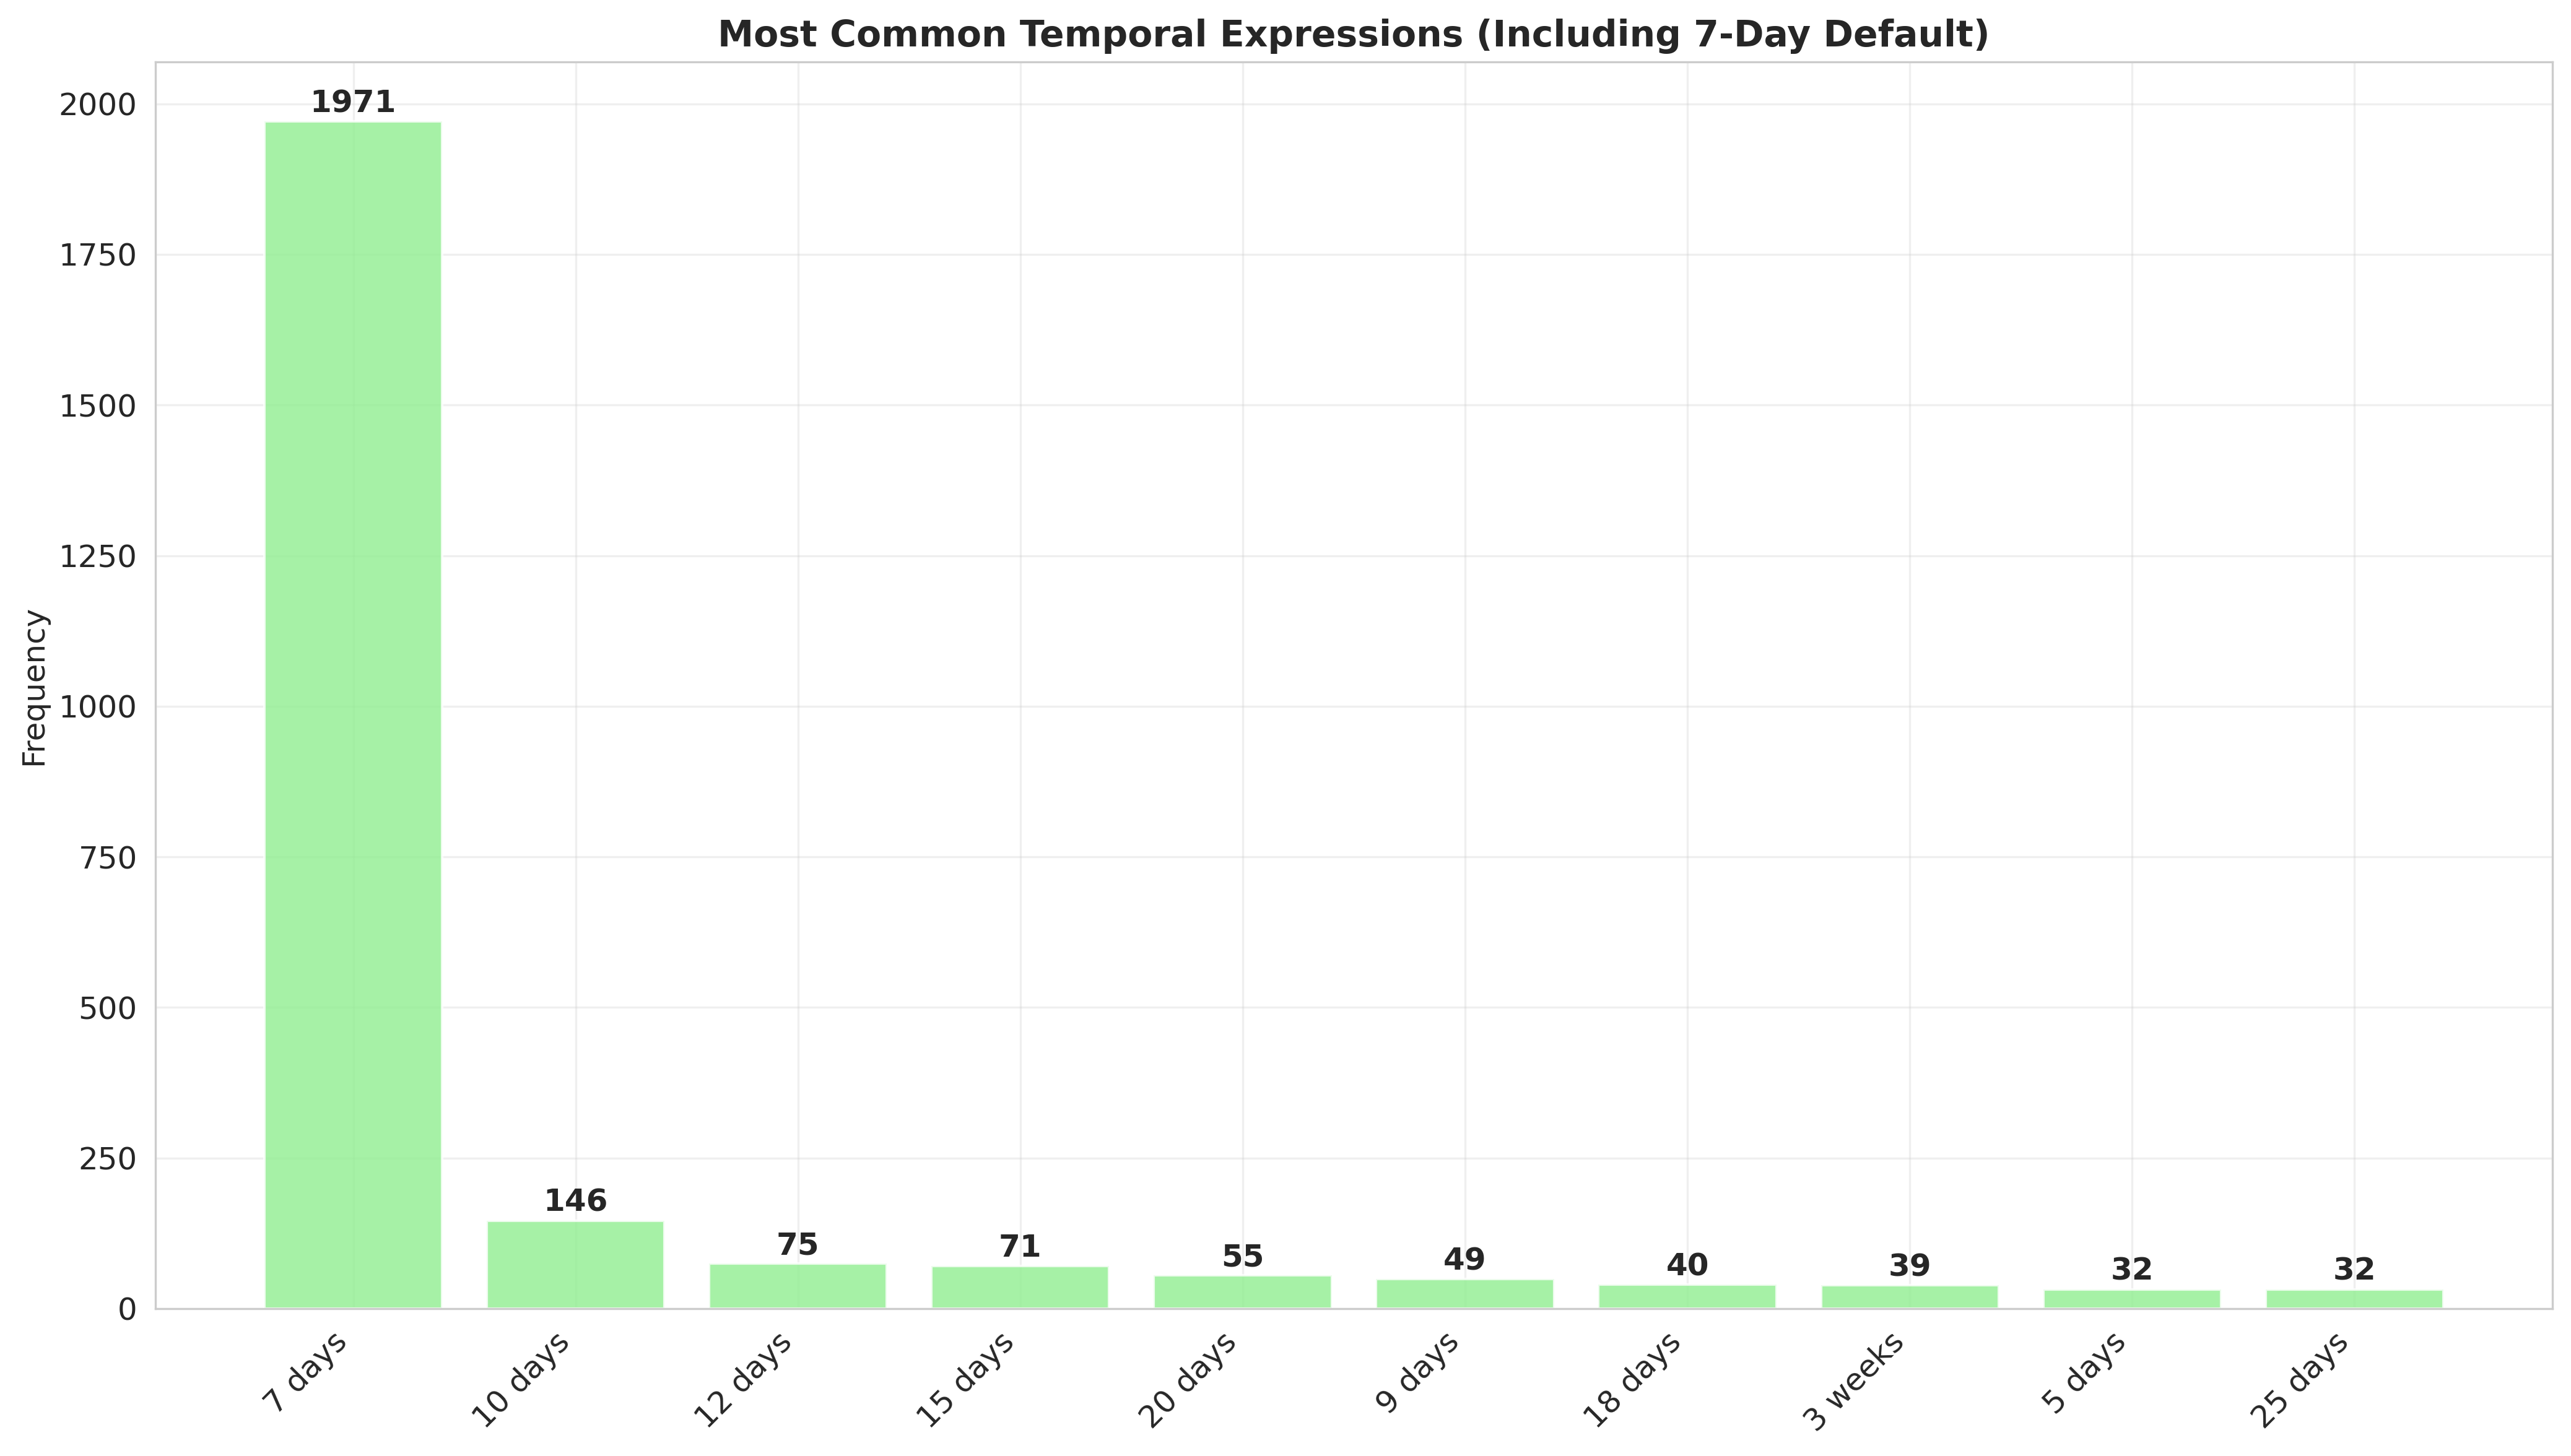

In [18]:
# Cell 6b: Explicit vs Vague Temporal Expressions
plt.figure(figsize=(14, 8))

# Combine explicit expressions and include "7 days" default
explicit_expressions = []
for expr_list in all_expressions.get('explicit_numeric', []):
    if isinstance(expr_list, str):
        explicit_expressions.append(expr_list)
    elif isinstance(expr_list, (list, tuple)):
        explicit_expressions.extend(expr_list)

# Add "7 days" for queries without explicit temporal mentions
queries_without_temporal = len([a for a in temporal_analysis if not a['temporal_patterns']])
explicit_expressions.extend(['7 days'] * queries_without_temporal)

if explicit_expressions:
    explicit_counter = Counter(explicit_expressions)
    top_explicit = explicit_counter.most_common(10)
    
    if top_explicit:
        labels, counts = zip(*top_explicit)
        bars = plt.bar(range(len(labels)), counts, color='lightgreen', alpha=0.8)
        plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
        plt.title('Most Common Temporal Expressions (Including 7-Day Default)', fontweight='bold', fontsize=14)
        plt.ylabel('Frequency')
        plt.grid(True, alpha=0.3)
        
        # Add value labels
        for i, (bar, count) in enumerate(zip(bars, counts)):
            plt.text(i, count + 5, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

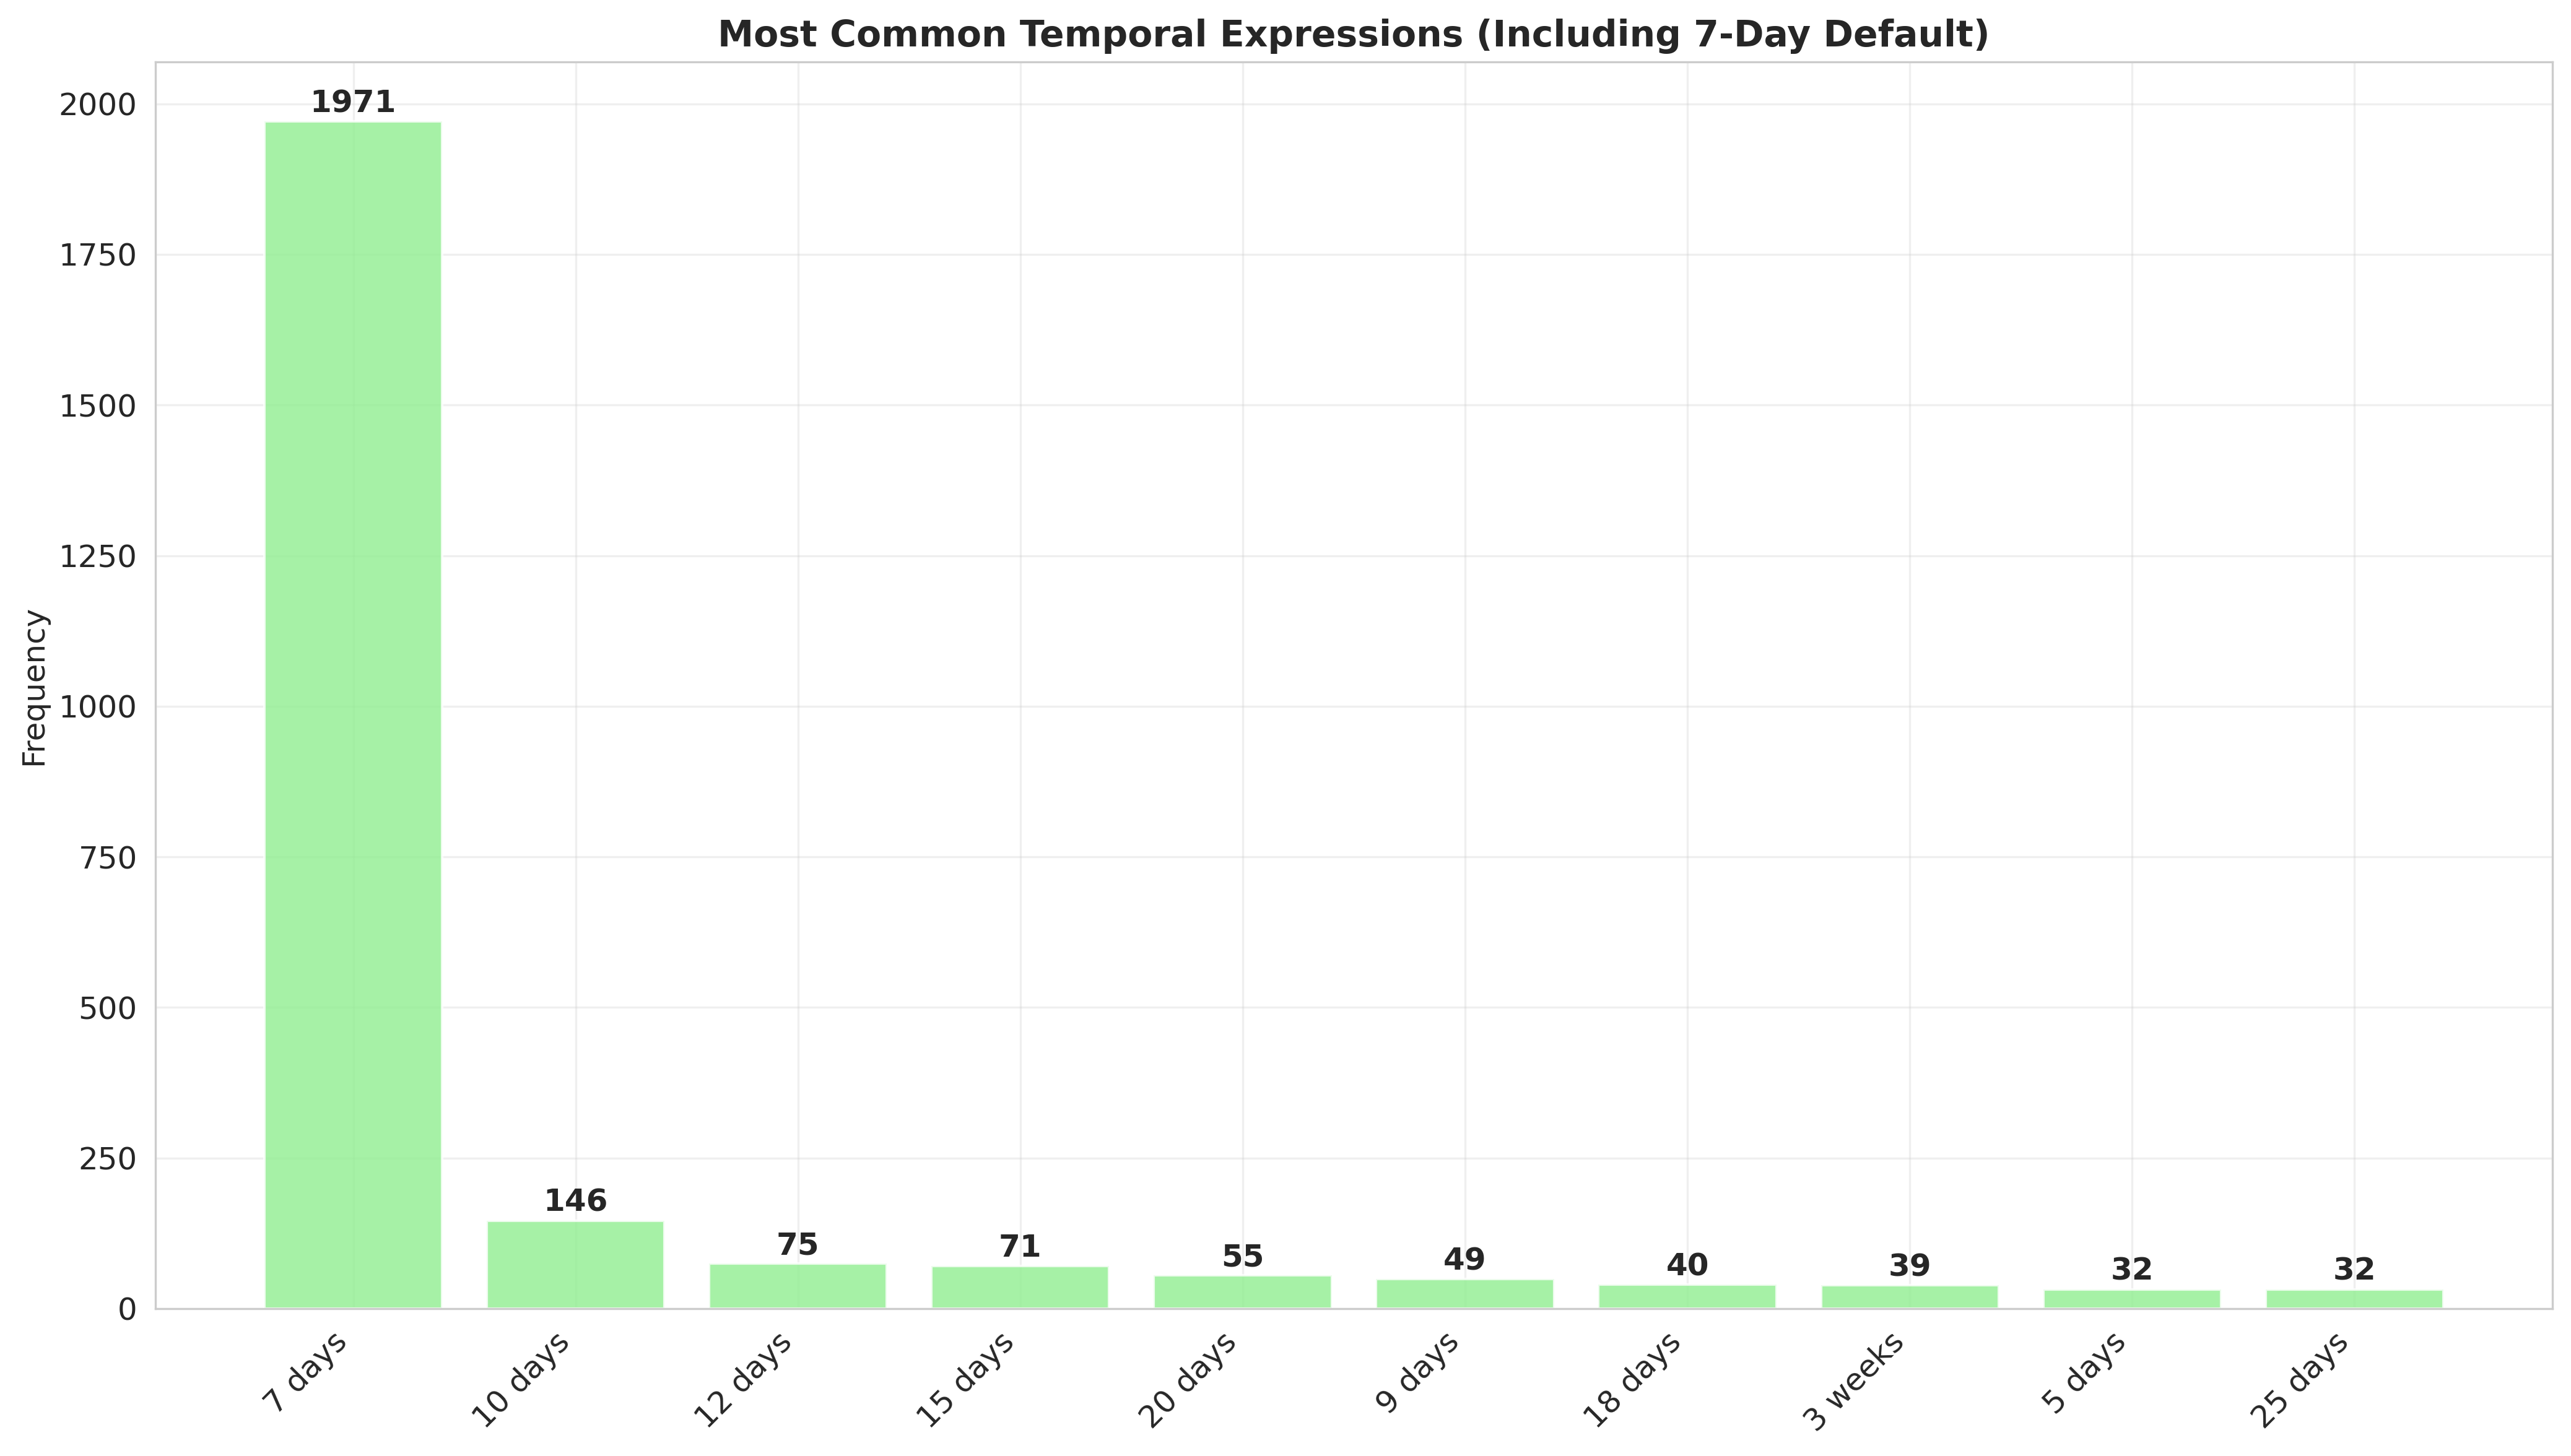

In [19]:
# Cell 6b: Explicit vs Vague Temporal Expressions
plt.figure(figsize=(14, 8))

# Combine explicit expressions and include "7 days" default
explicit_expressions = []
for expr_list in all_expressions.get('explicit_numeric', []):
    if isinstance(expr_list, str):
        explicit_expressions.append(expr_list)
    elif isinstance(expr_list, (list, tuple)):
        explicit_expressions.extend(expr_list)

# Add "7 days" for queries without explicit temporal mentions
queries_without_temporal = len([a for a in temporal_analysis if not a['temporal_patterns']])
explicit_expressions.extend(['7 days'] * queries_without_temporal)

if explicit_expressions:
    explicit_counter = Counter(explicit_expressions)
    top_explicit = explicit_counter.most_common(10)
    
    if top_explicit:
        labels, counts = zip(*top_explicit)
        bars = plt.bar(range(len(labels)), counts, color='lightgreen', alpha=0.8)
        plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
        plt.title('Most Common Temporal Expressions (Including 7-Day Default)', fontweight='bold', fontsize=14)
        plt.ylabel('Frequency')
        plt.grid(True, alpha=0.3)
        
        # Add value labels
        for i, (bar, count) in enumerate(zip(bars, counts)):
            plt.text(i, count + 5, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

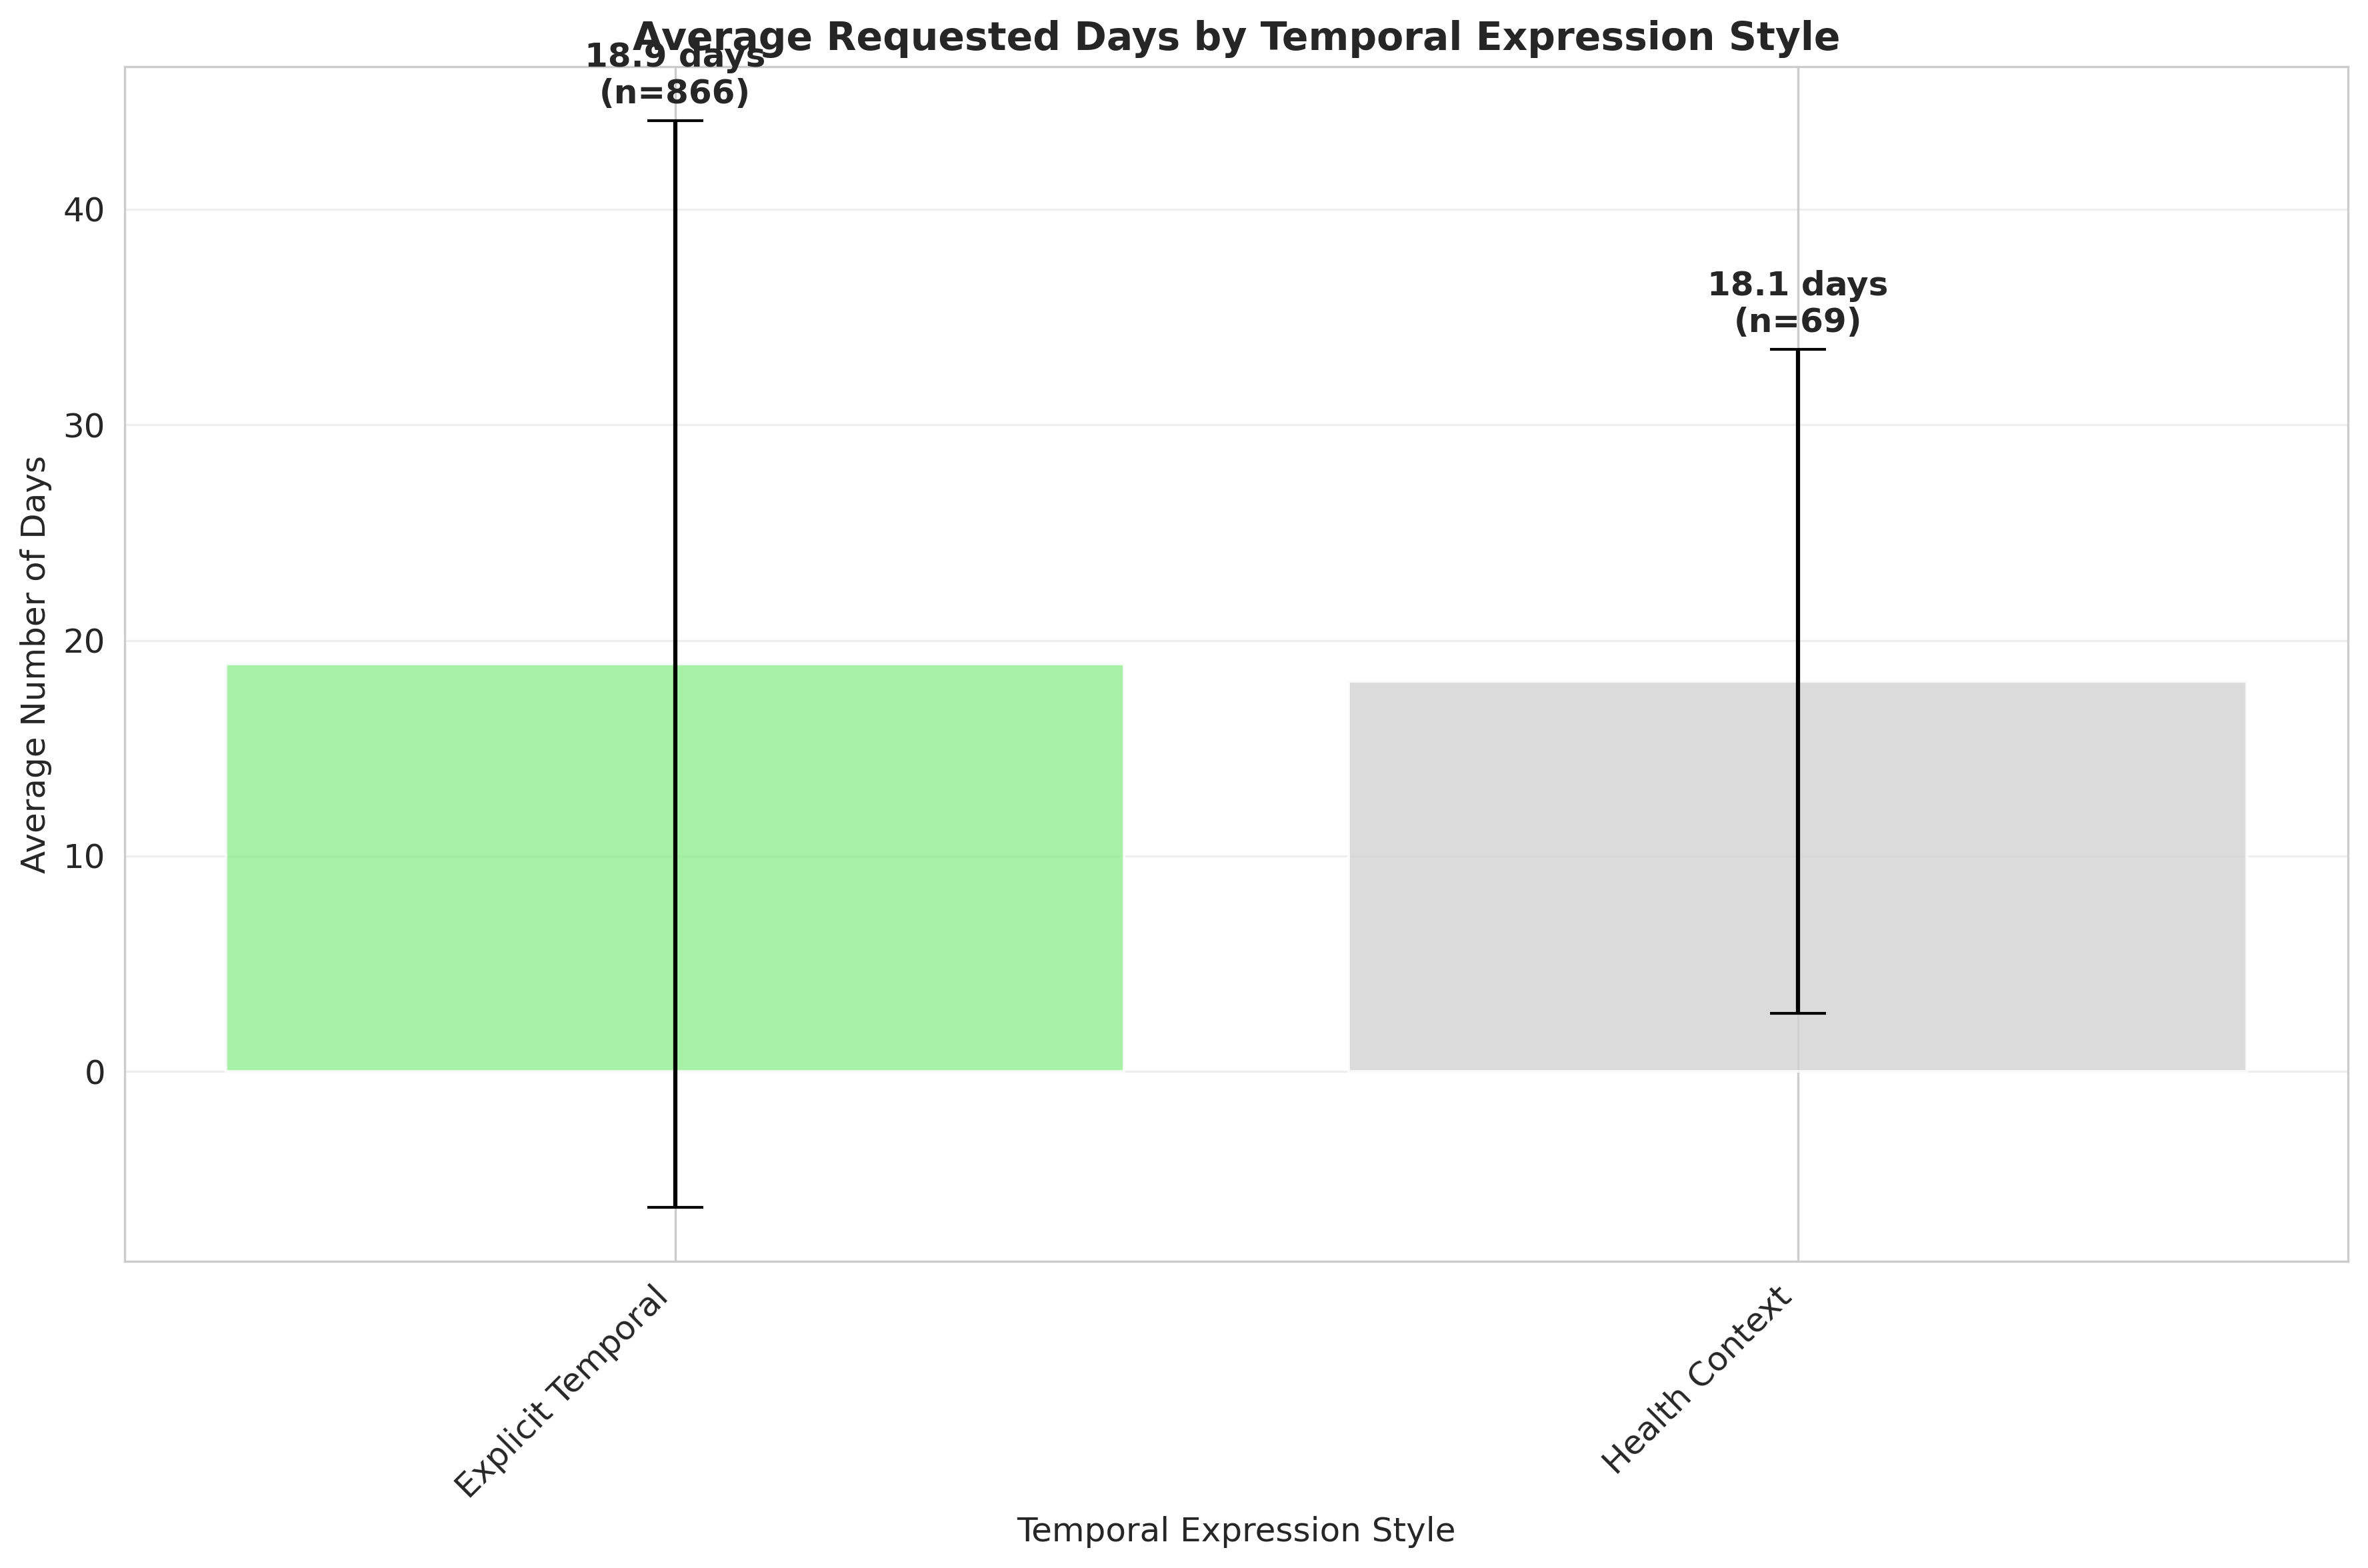

In [21]:
# Cell 6c: Temporal Style vs Requested Days - Bar Chart Version
plt.figure(figsize=(12, 8))

# Calculate statistics for each temporal style
style_stats = {}
for style, days_list in pattern_numdays.items():
    if days_list:
        style_stats[style] = {
            'mean': np.mean(days_list),
            'std': np.std(days_list),
            'count': len(days_list)
        }

if style_stats:
    styles = list(style_stats.keys())
    means = [style_stats[style]['mean'] for style in styles]
    stds = [style_stats[style]['std'] for style in styles]
    counts = [style_stats[style]['count'] for style in styles]
    
    colors = ['lightblue', 'lightcoral', 'lightgreen', 'lightgray']
    bars = plt.bar(styles, means, yerr=stds, capsize=10, color=colors[:len(styles)], alpha=0.8)
    
    plt.title('Average Requested Days by Temporal Expression Style', fontweight='bold', fontsize=14)
    plt.xlabel('Temporal Expression Style')
    plt.ylabel('Average Number of Days')
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, alpha=0.3, axis='y')
    
    # Add value labels and sample sizes
    for i, (bar, mean_val, count) in enumerate(zip(bars, means, counts)):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + stds[i] + 0.5,
                f'{mean_val:.1f} days\n(n={count})', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2430: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


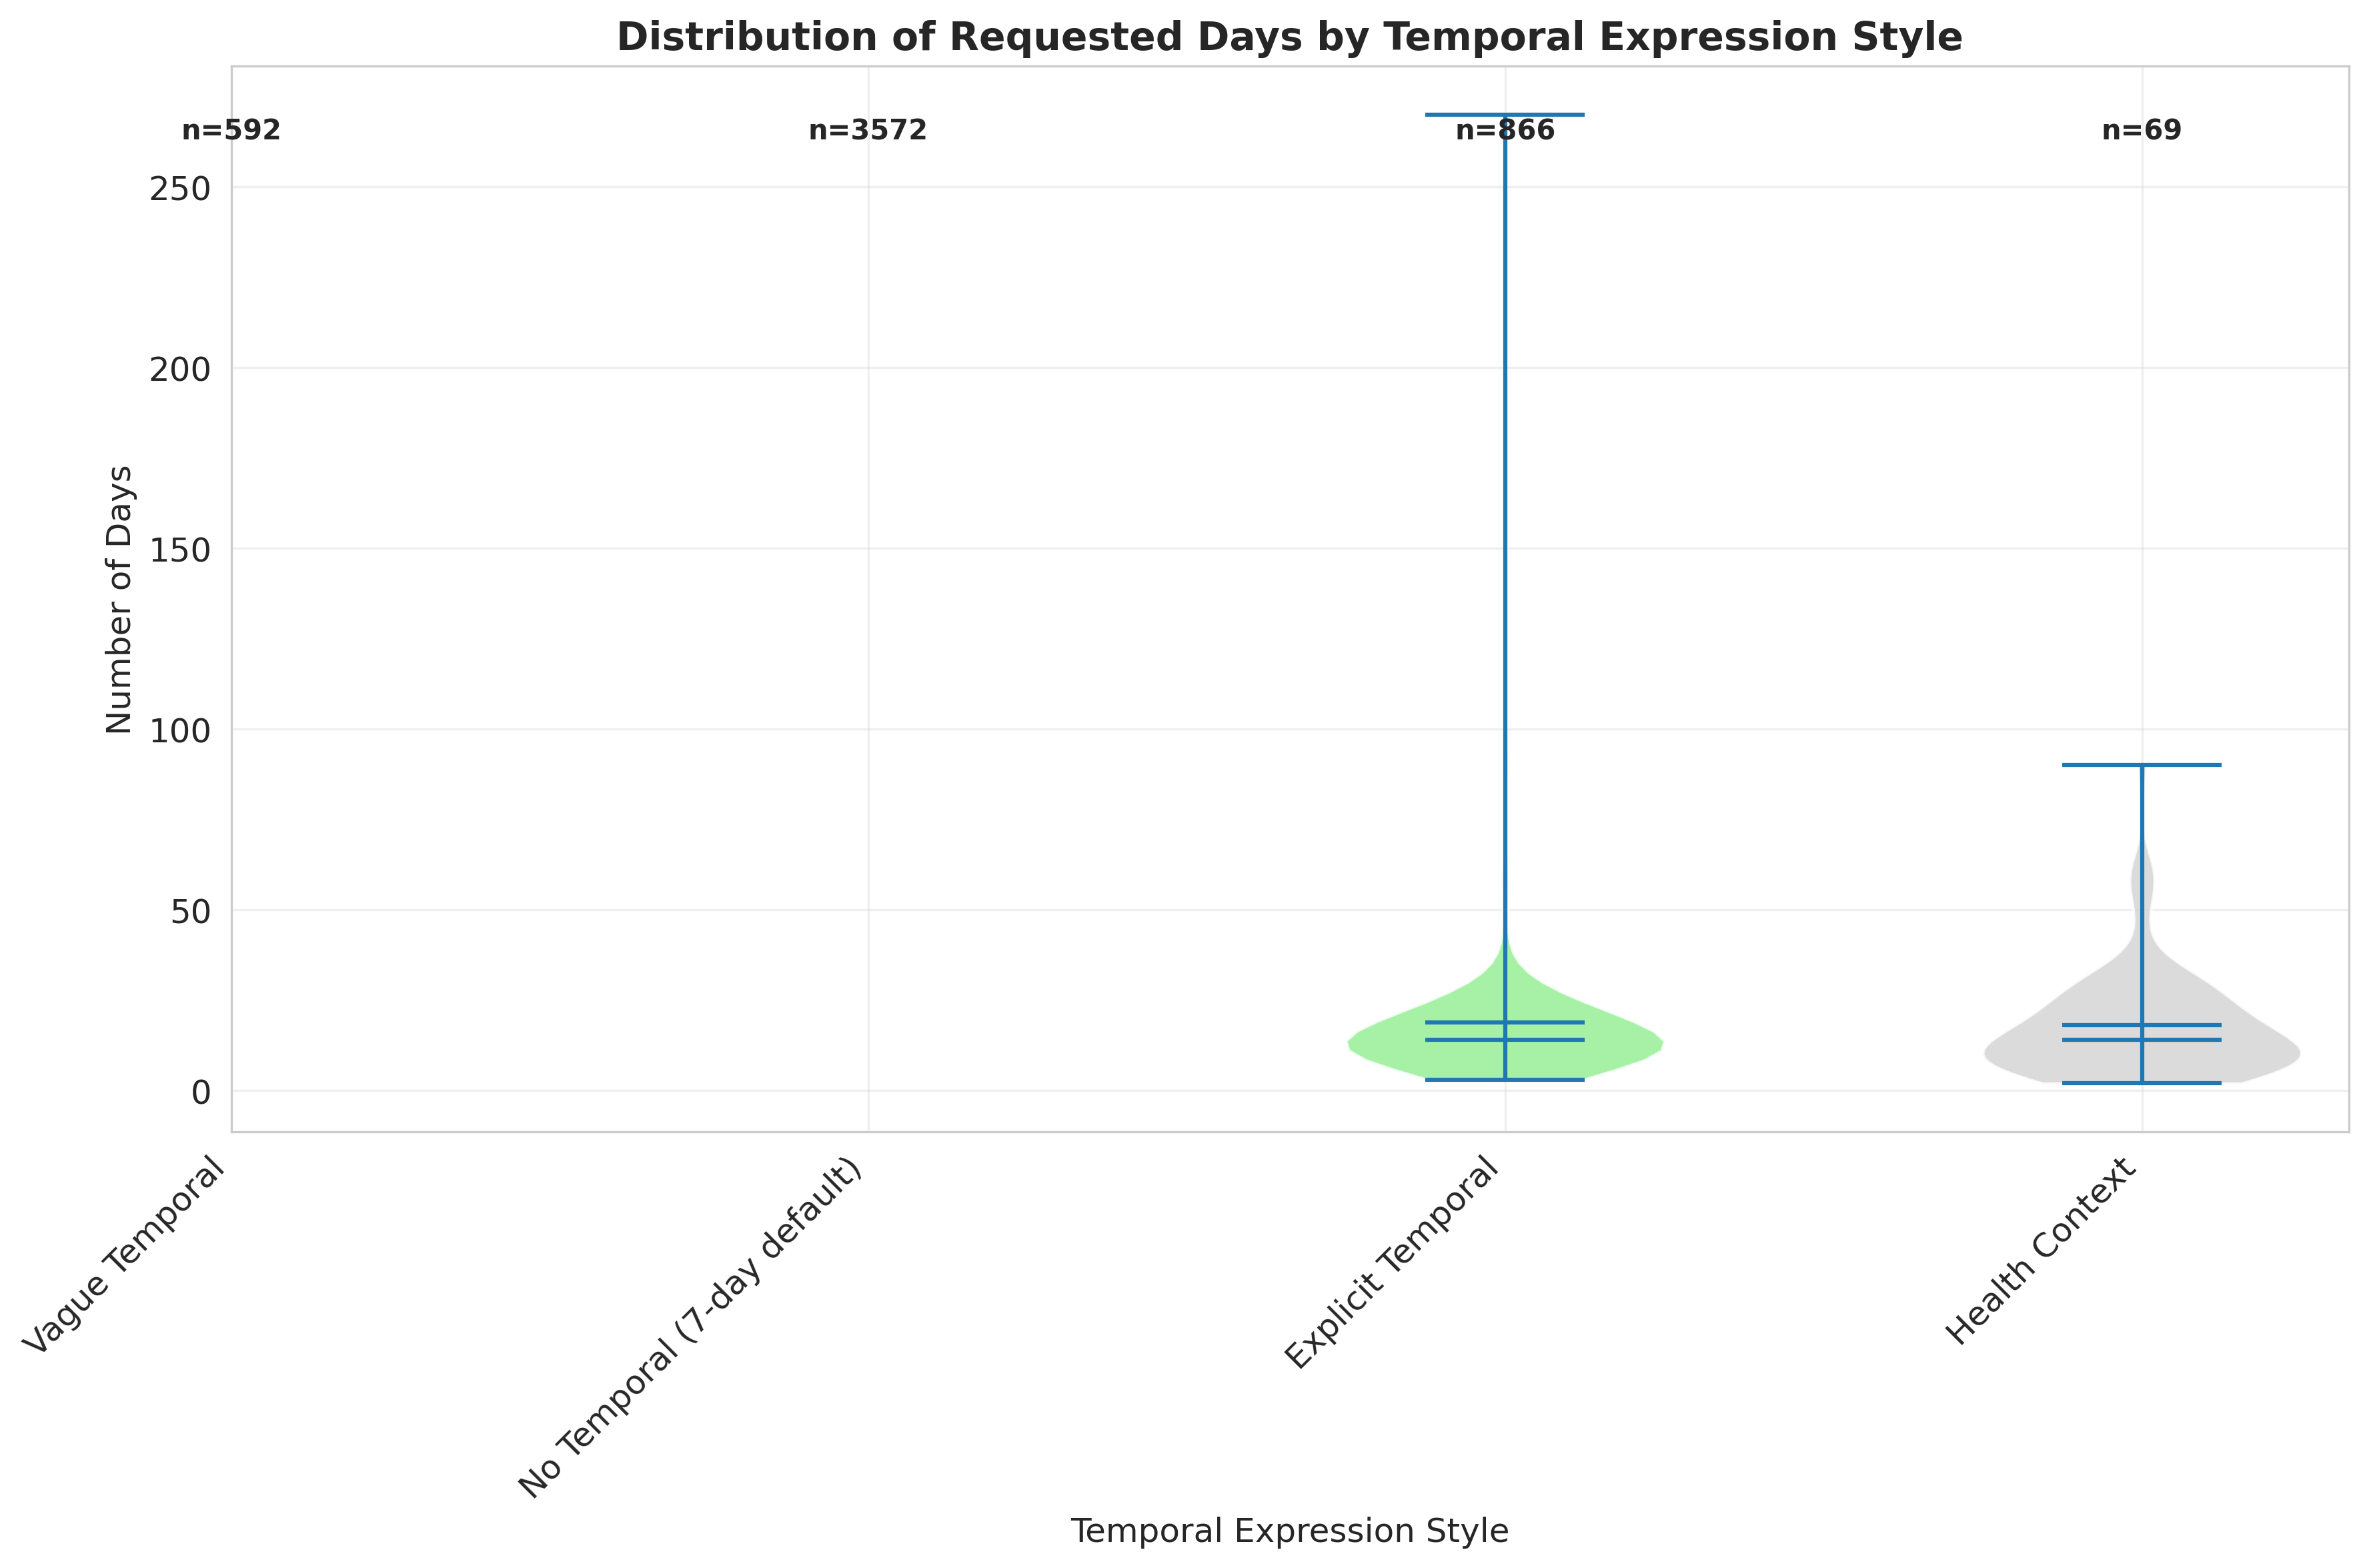

In [22]:
# Cell 6c: Temporal Style vs Requested Days - Violin Plot Version
plt.figure(figsize=(12, 8))

if pattern_numdays:
    labels = list(pattern_numdays.keys())
    data = [pattern_numdays[label] for label in labels]
    
    parts = plt.violinplot(data, positions=range(1, len(labels)+1), showmeans=True, showmedians=True)
    
    # Color the violin plots
    colors = ['lightblue', 'lightcoral', 'lightgreen', 'lightgray']
    for pc, color in zip(parts['bodies'], colors[:len(parts['bodies'])]):
        pc.set_facecolor(color)
        pc.set_alpha(0.8)
    
    plt.title('Distribution of Requested Days by Temporal Expression Style', fontweight='bold', fontsize=14)
    plt.xlabel('Temporal Expression Style')
    plt.ylabel('Number of Days')
    plt.xticks(range(1, len(labels)+1), labels, rotation=45, ha='right')
    plt.grid(True, alpha=0.3)
    
    # Add sample size annotations
    for i, label in enumerate(labels):
        sample_size = len(pattern_numdays[label])
        plt.text(i+1, plt.ylim()[1]*0.95, f'n={sample_size}', 
                ha='center', va='top', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

TypeError: 'float' object cannot be interpreted as an integer

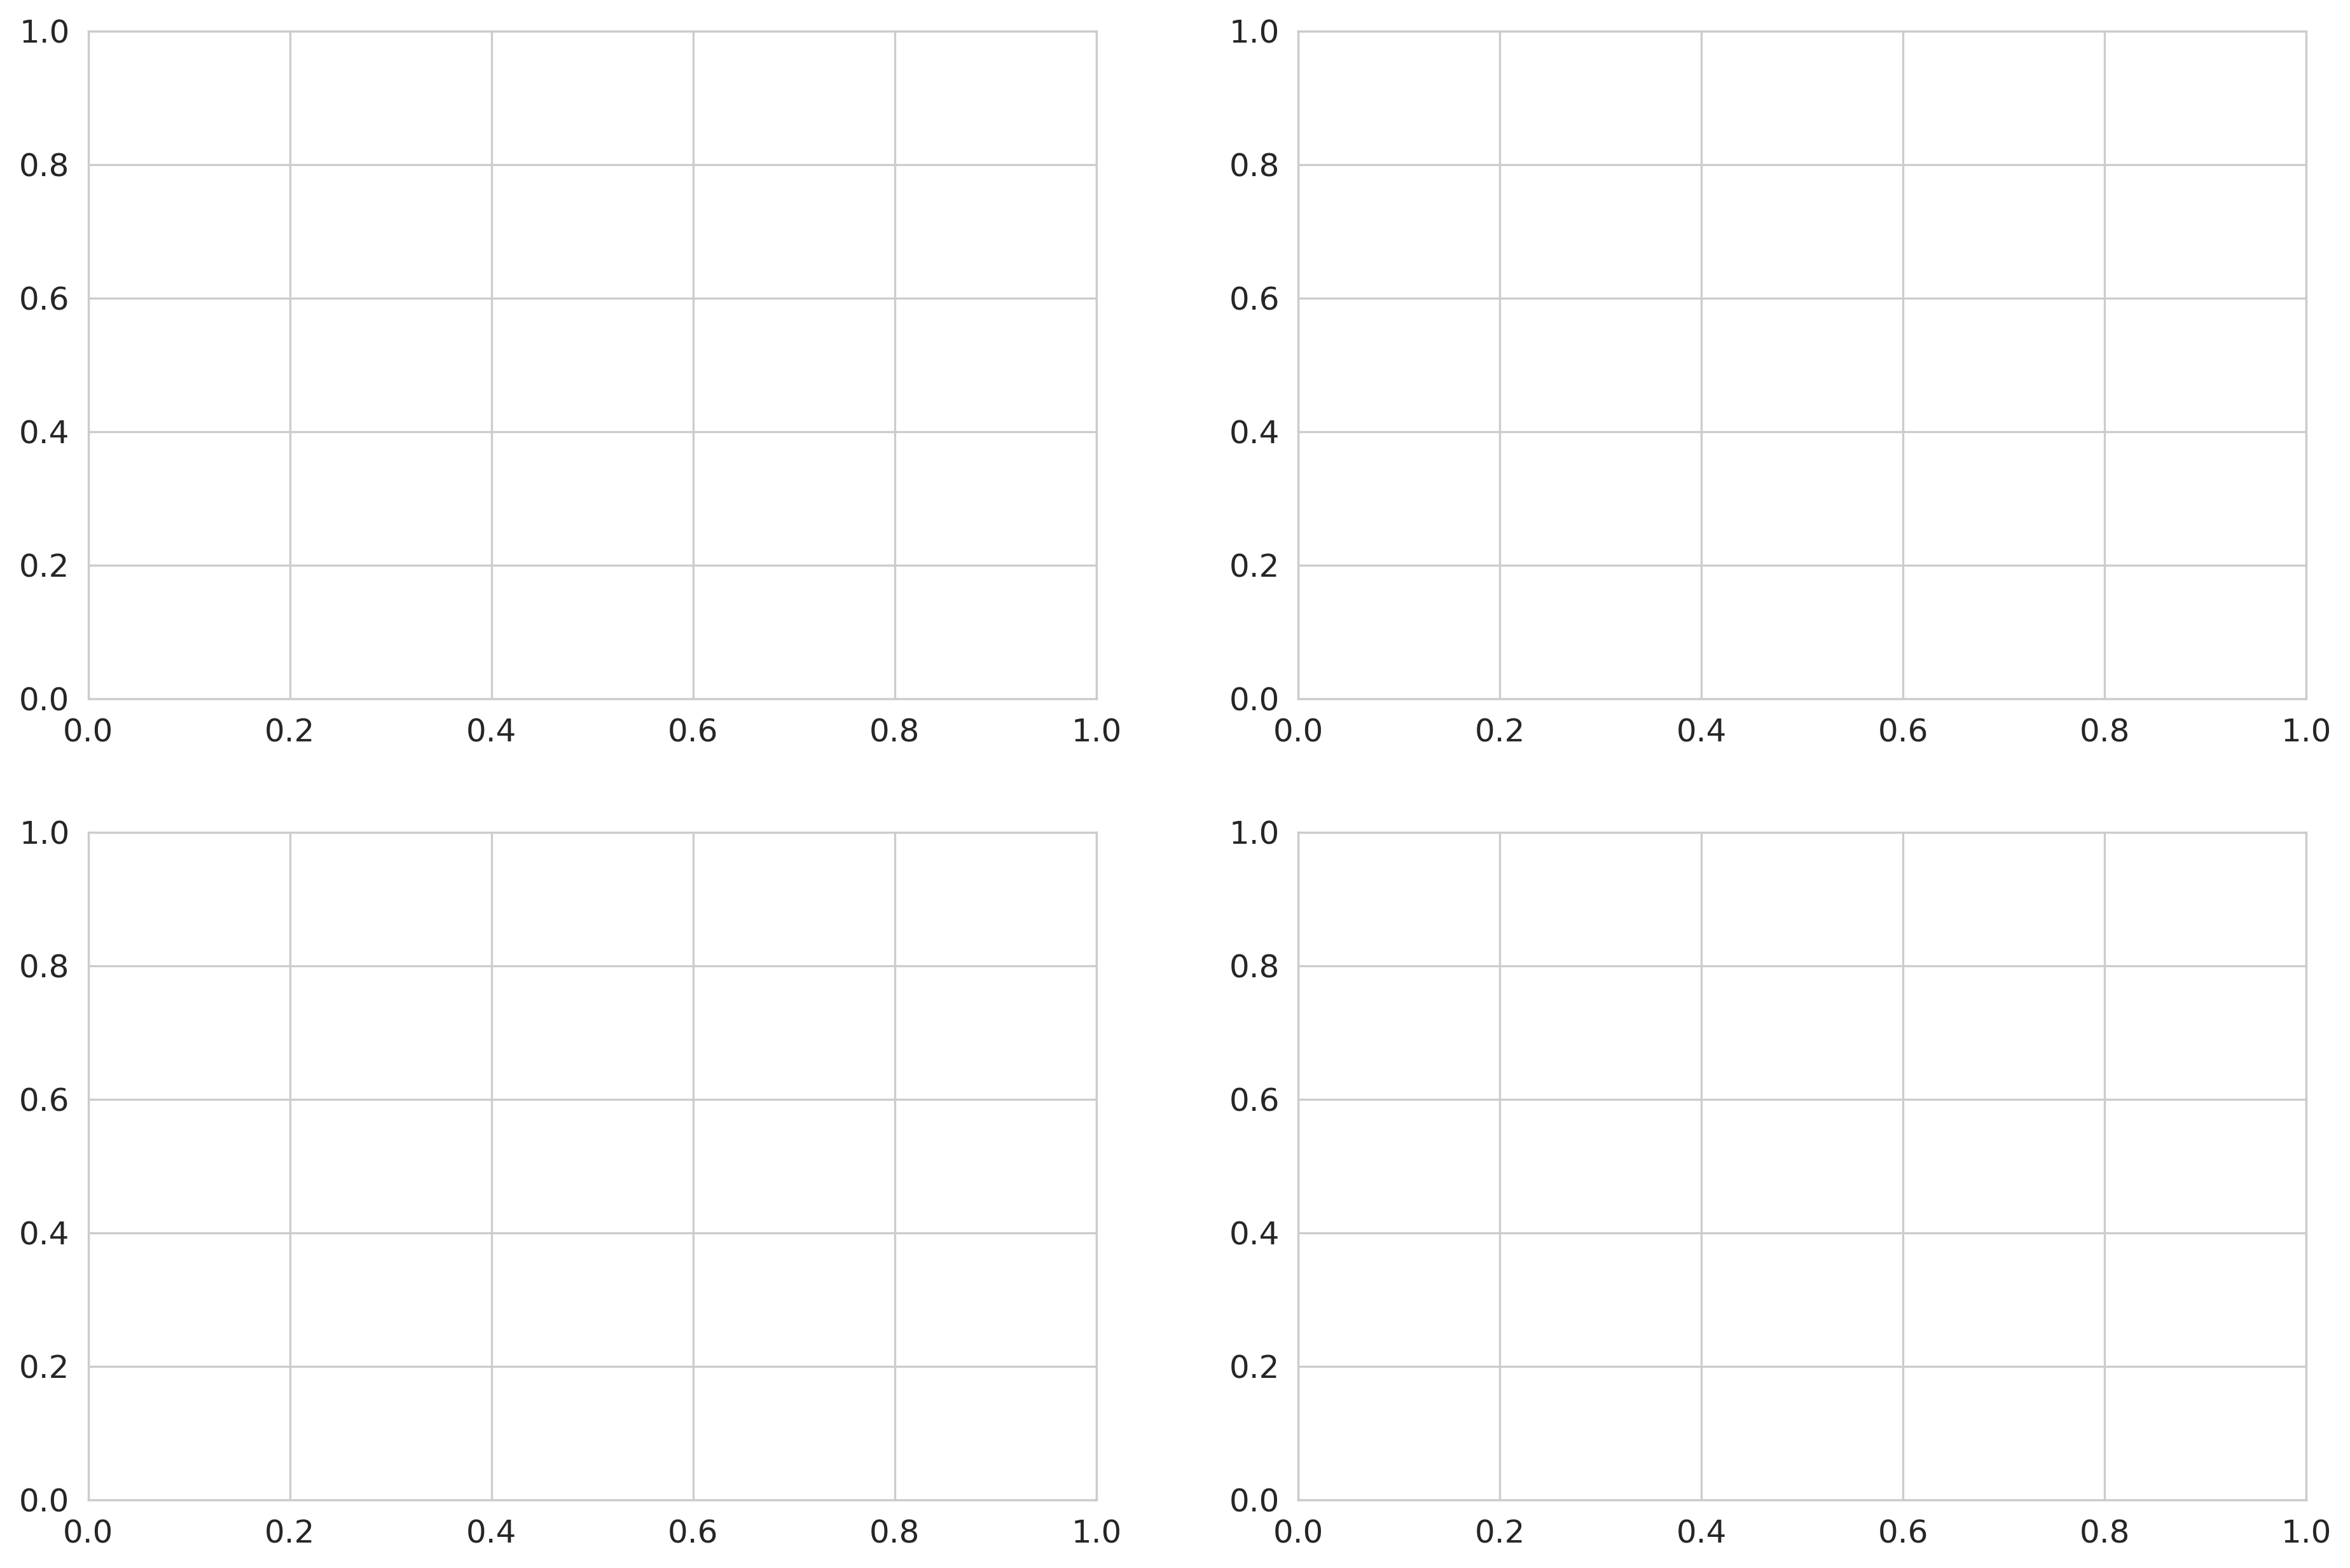

In [23]:
# Cell 6c: Temporal Style vs Requested Days - Histogram Comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

colors = ['lightblue', 'lightcoral', 'lightgreen', 'lightgray']
styles = list(pattern_numdays.keys())

for i, (style, ax, color) in enumerate(zip(styles, axes, colors)):
    if i < len(styles):
        days_data = pattern_numdays[style]
        
        ax.hist(days_data, bins=range(1, max(days_data)+2), alpha=0.8, color=color, edgecolor='black')
        ax.set_title(f'{style}\n(n={len(days_data)}, avg={np.mean(days_data):.1f} days)', 
                    fontweight='bold', fontsize=12)
        ax.set_xlabel('Number of Days')
        ax.set_ylabel('Frequency')
        ax.grid(True, alpha=0.3)
        
        # Add mean line
        ax.axvline(np.mean(days_data), color='red', linestyle='--', linewidth=2, 
                  label=f'Mean: {np.mean(days_data):.1f}')
        ax.legend()
    else:
        ax.remove()

plt.suptitle('Distribution of Requested Days by Temporal Expression Style', 
             fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

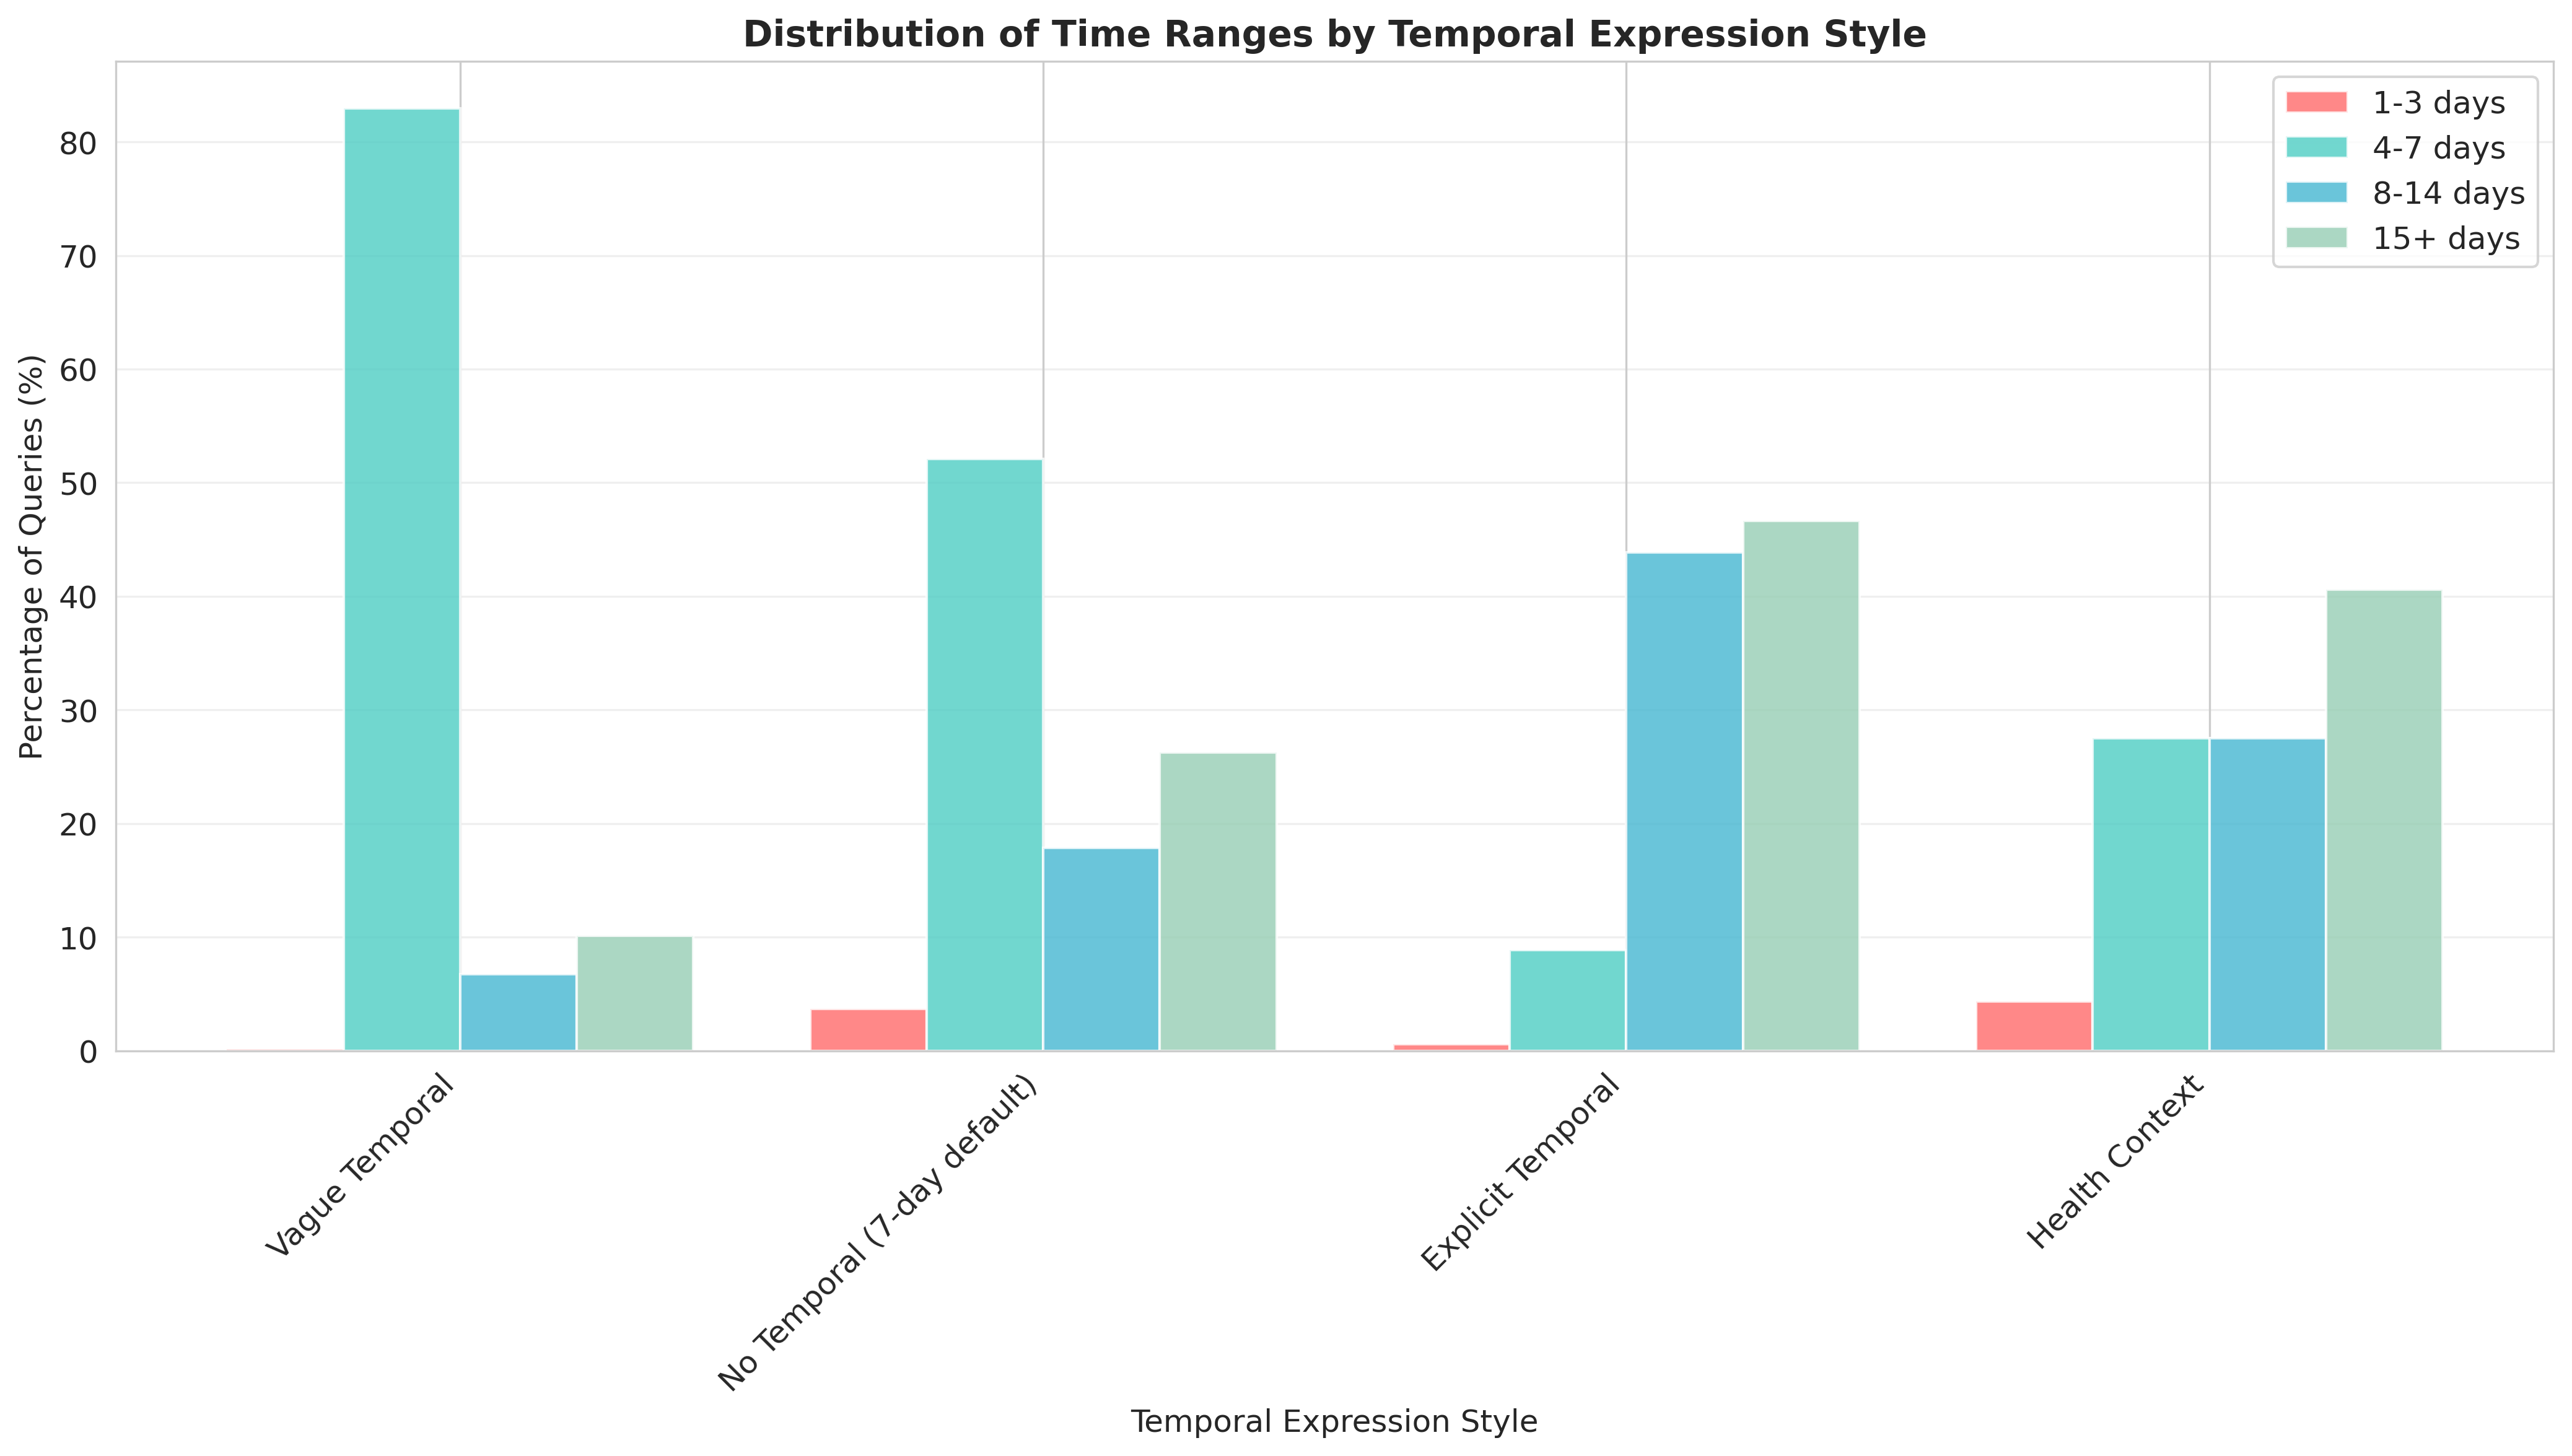

In [24]:
# Cell 6c: Temporal Style vs Requested Days - Grouped Bar Chart
plt.figure(figsize=(14, 8))

# Create day value counts for each style
day_ranges = {'1-3 days': [], '4-7 days': [], '8-14 days': [], '15+ days': []}

for style, days_list in pattern_numdays.items():
    range_counts = {'1-3 days': 0, '4-7 days': 0, '8-14 days': 0, '15+ days': 0}
    
    for days in days_list:
        if days <= 3:
            range_counts['1-3 days'] += 1
        elif days <= 7:
            range_counts['4-7 days'] += 1
        elif days <= 14:
            range_counts['8-14 days'] += 1
        else:
            range_counts['15+ days'] += 1
    
    # Convert to percentages
    total = len(days_list)
    for range_name in range_counts:
        day_ranges[range_name].append((range_counts[range_name] / total) * 100 if total > 0 else 0)

# Plot grouped bars
x = np.arange(len(pattern_numdays.keys()))
width = 0.2
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

for i, (range_name, color) in enumerate(zip(day_ranges.keys(), colors)):
    plt.bar(x + i*width, day_ranges[range_name], width, label=range_name, color=color, alpha=0.8)

plt.title('Distribution of Time Ranges by Temporal Expression Style', fontweight='bold', fontsize=14)
plt.xlabel('Temporal Expression Style')
plt.ylabel('Percentage of Queries (%)')
plt.xticks(x + width*1.5, pattern_numdays.keys(), rotation=45, ha='right')
plt.legend()
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

🧠 MENTAL HEALTH VOCABULARY ANALYSIS
🔍 Analyzing mental health vocabulary in queries...


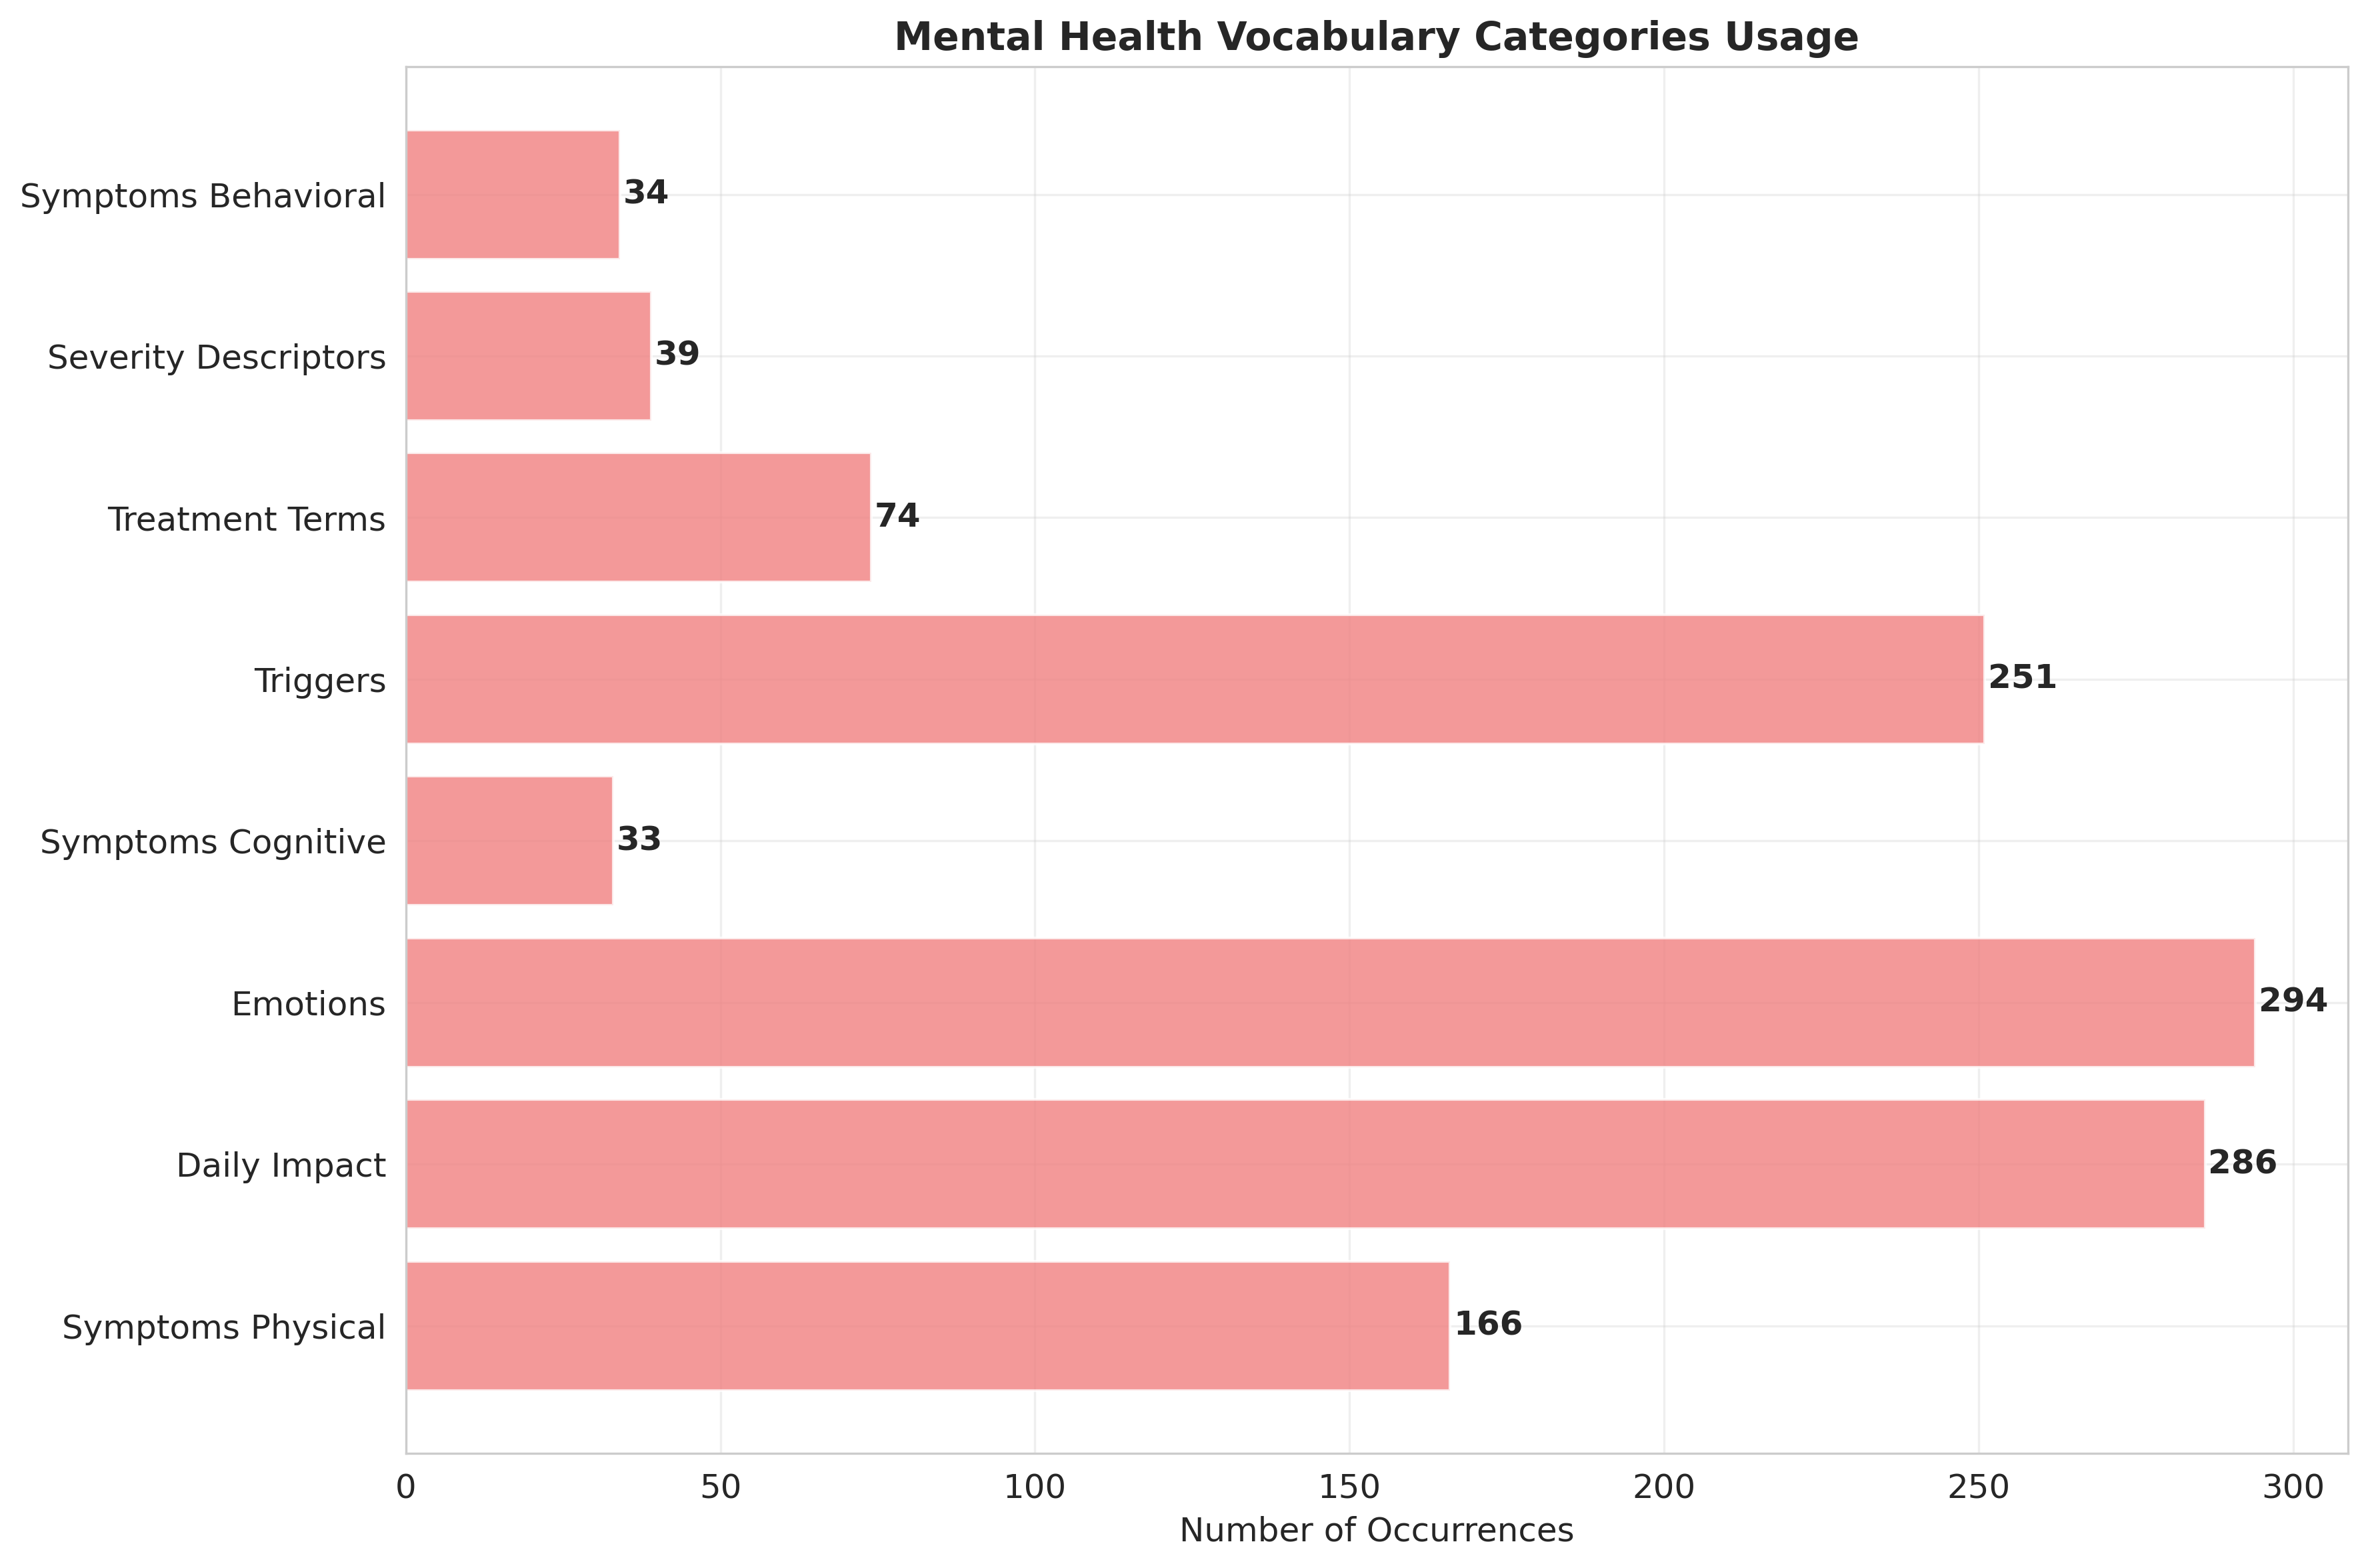

In [10]:
# Cell 7a: Mental Health Category Frequency
from wordcloud import WordCloud
import re

print("🧠 MENTAL HEALTH VOCABULARY ANALYSIS")
print("=" * 45)

# Define comprehensive mental health vocabulary categories
mental_health_vocabulary = {
    'emotions': [
        'anxious', 'anxiety', 'worried', 'stress', 'stressed', 'depressed', 'depression', 
        'sad', 'sadness', 'angry', 'anger', 'frustrated', 'overwhelmed', 'hopeless',
        'fear', 'scared', 'panic', 'nervous', 'irritated', 'moody', 'upset', 'emotional'
    ],
    'symptoms_physical': [
        'tired', 'fatigue', 'exhausted', 'headache', 'pain', 'ache', 'nausea',
        'dizzy', 'shaky', 'trembling', 'sweating', 'heart racing', 'breathless',
        'insomnia', 'sleepless', 'restless', 'tense', 'muscle tension'
    ],
    'symptoms_cognitive': [
        'memory', 'forget', 'forgetful', 'concentration', 'focus', 'distracted',
        'confused', 'unclear', 'foggy', 'racing thoughts', 'overthinking',
        'intrusive thoughts', 'worry', 'ruminating', 'mind blank'
    ],
    'symptoms_behavioral': [
        'avoid', 'avoiding', 'isolation', 'withdraw', 'procrastinate',
        'compulsive', 'repetitive', 'habits', 'rituals', 'checking',
        'perfectionism', 'control', 'obsessive'
    ],
    'severity_descriptors': [
        'severe', 'mild', 'moderate', 'intense', 'extreme', 'overwhelming',
        'unbearable', 'manageable', 'slight', 'significant', 'major', 'minor',
        'chronic', 'acute', 'persistent', 'constant', 'occasional'
    ],
    'treatment_terms': [
        'therapy', 'therapist', 'counseling', 'medication', 'antidepressant',
        'treatment', 'doctor', 'psychiatrist', 'psychologist', 'counselor',
        'prescription', 'dose', 'side effects', 'coping', 'support'
    ],
    'daily_impact': [
        'work', 'job', 'productivity', 'performance', 'relationship', 'family',
        'social', 'daily life', 'routine', 'activities', 'functioning',
        'quality of life', 'disrupted', 'affecting', 'interfering'
    ],
    'triggers': [
        'trigger', 'triggered', 'stressful', 'overwhelming situation', 'conflict',
        'deadline', 'pressure', 'change', 'transition', 'loss', 'grief',
        'trauma', 'abuse', 'bullying', 'rejection'
    ]
}

# Extract mental health terms from queries
def extract_mental_health_terms(text):
    """Extract mental health related terms from text"""
    if pd.isna(text):
        return {}
    
    text_lower = str(text).lower()
    found_terms = {}
    
    for category, terms in mental_health_vocabulary.items():
        found_in_category = []
        for term in terms:
            # Use word boundaries to match whole words
            pattern = r'\b' + re.escape(term) + r'\b'
            if re.search(pattern, text_lower):
                found_in_category.append(term)
        
        if found_in_category:
            found_terms[category] = found_in_category
    
    return found_terms

# Analyze all queries for mental health vocabulary
mh_vocab_analysis = []
category_frequency = defaultdict(int)
term_frequency = defaultdict(int)
all_mh_terms = []

print("🔍 Analyzing mental health vocabulary in queries...")

for idx, row in df.iterrows():
    query = row.get('query', '')
    if pd.notna(query):
        mh_terms = extract_mental_health_terms(query)
        
        vocab_entry = {
            'query_idx': idx,
            'query': query,
            'type': row.get('type', 'unknown'),
            'mh_terms': mh_terms,
            'categories_found': list(mh_terms.keys()),
            'total_mh_terms': sum(len(terms) for terms in mh_terms.values())
        }
        
        mh_vocab_analysis.append(vocab_entry)
        
        # Count frequencies
        for category, terms in mh_terms.items():
            category_frequency[category] += len(terms)
            for term in terms:
                term_frequency[term] += 1
                all_mh_terms.append(term)

# Figure 1: Mental Health Category Usage
plt.figure(figsize=(12, 8))
if category_frequency:
    categories = list(category_frequency.keys())
    cat_counts = list(category_frequency.values())
    
    # Clean category names for display
    clean_categories = [cat.replace('_', ' ').title() for cat in categories]
    
    bars = plt.barh(clean_categories, cat_counts, color='lightcoral', alpha=0.8)
    plt.title('Mental Health Vocabulary Categories Usage', fontweight='bold', fontsize=14)
    plt.xlabel('Number of Occurrences')
    plt.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, count in zip(bars, cat_counts):
        width = bar.get_width()
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
                f'{count}', ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

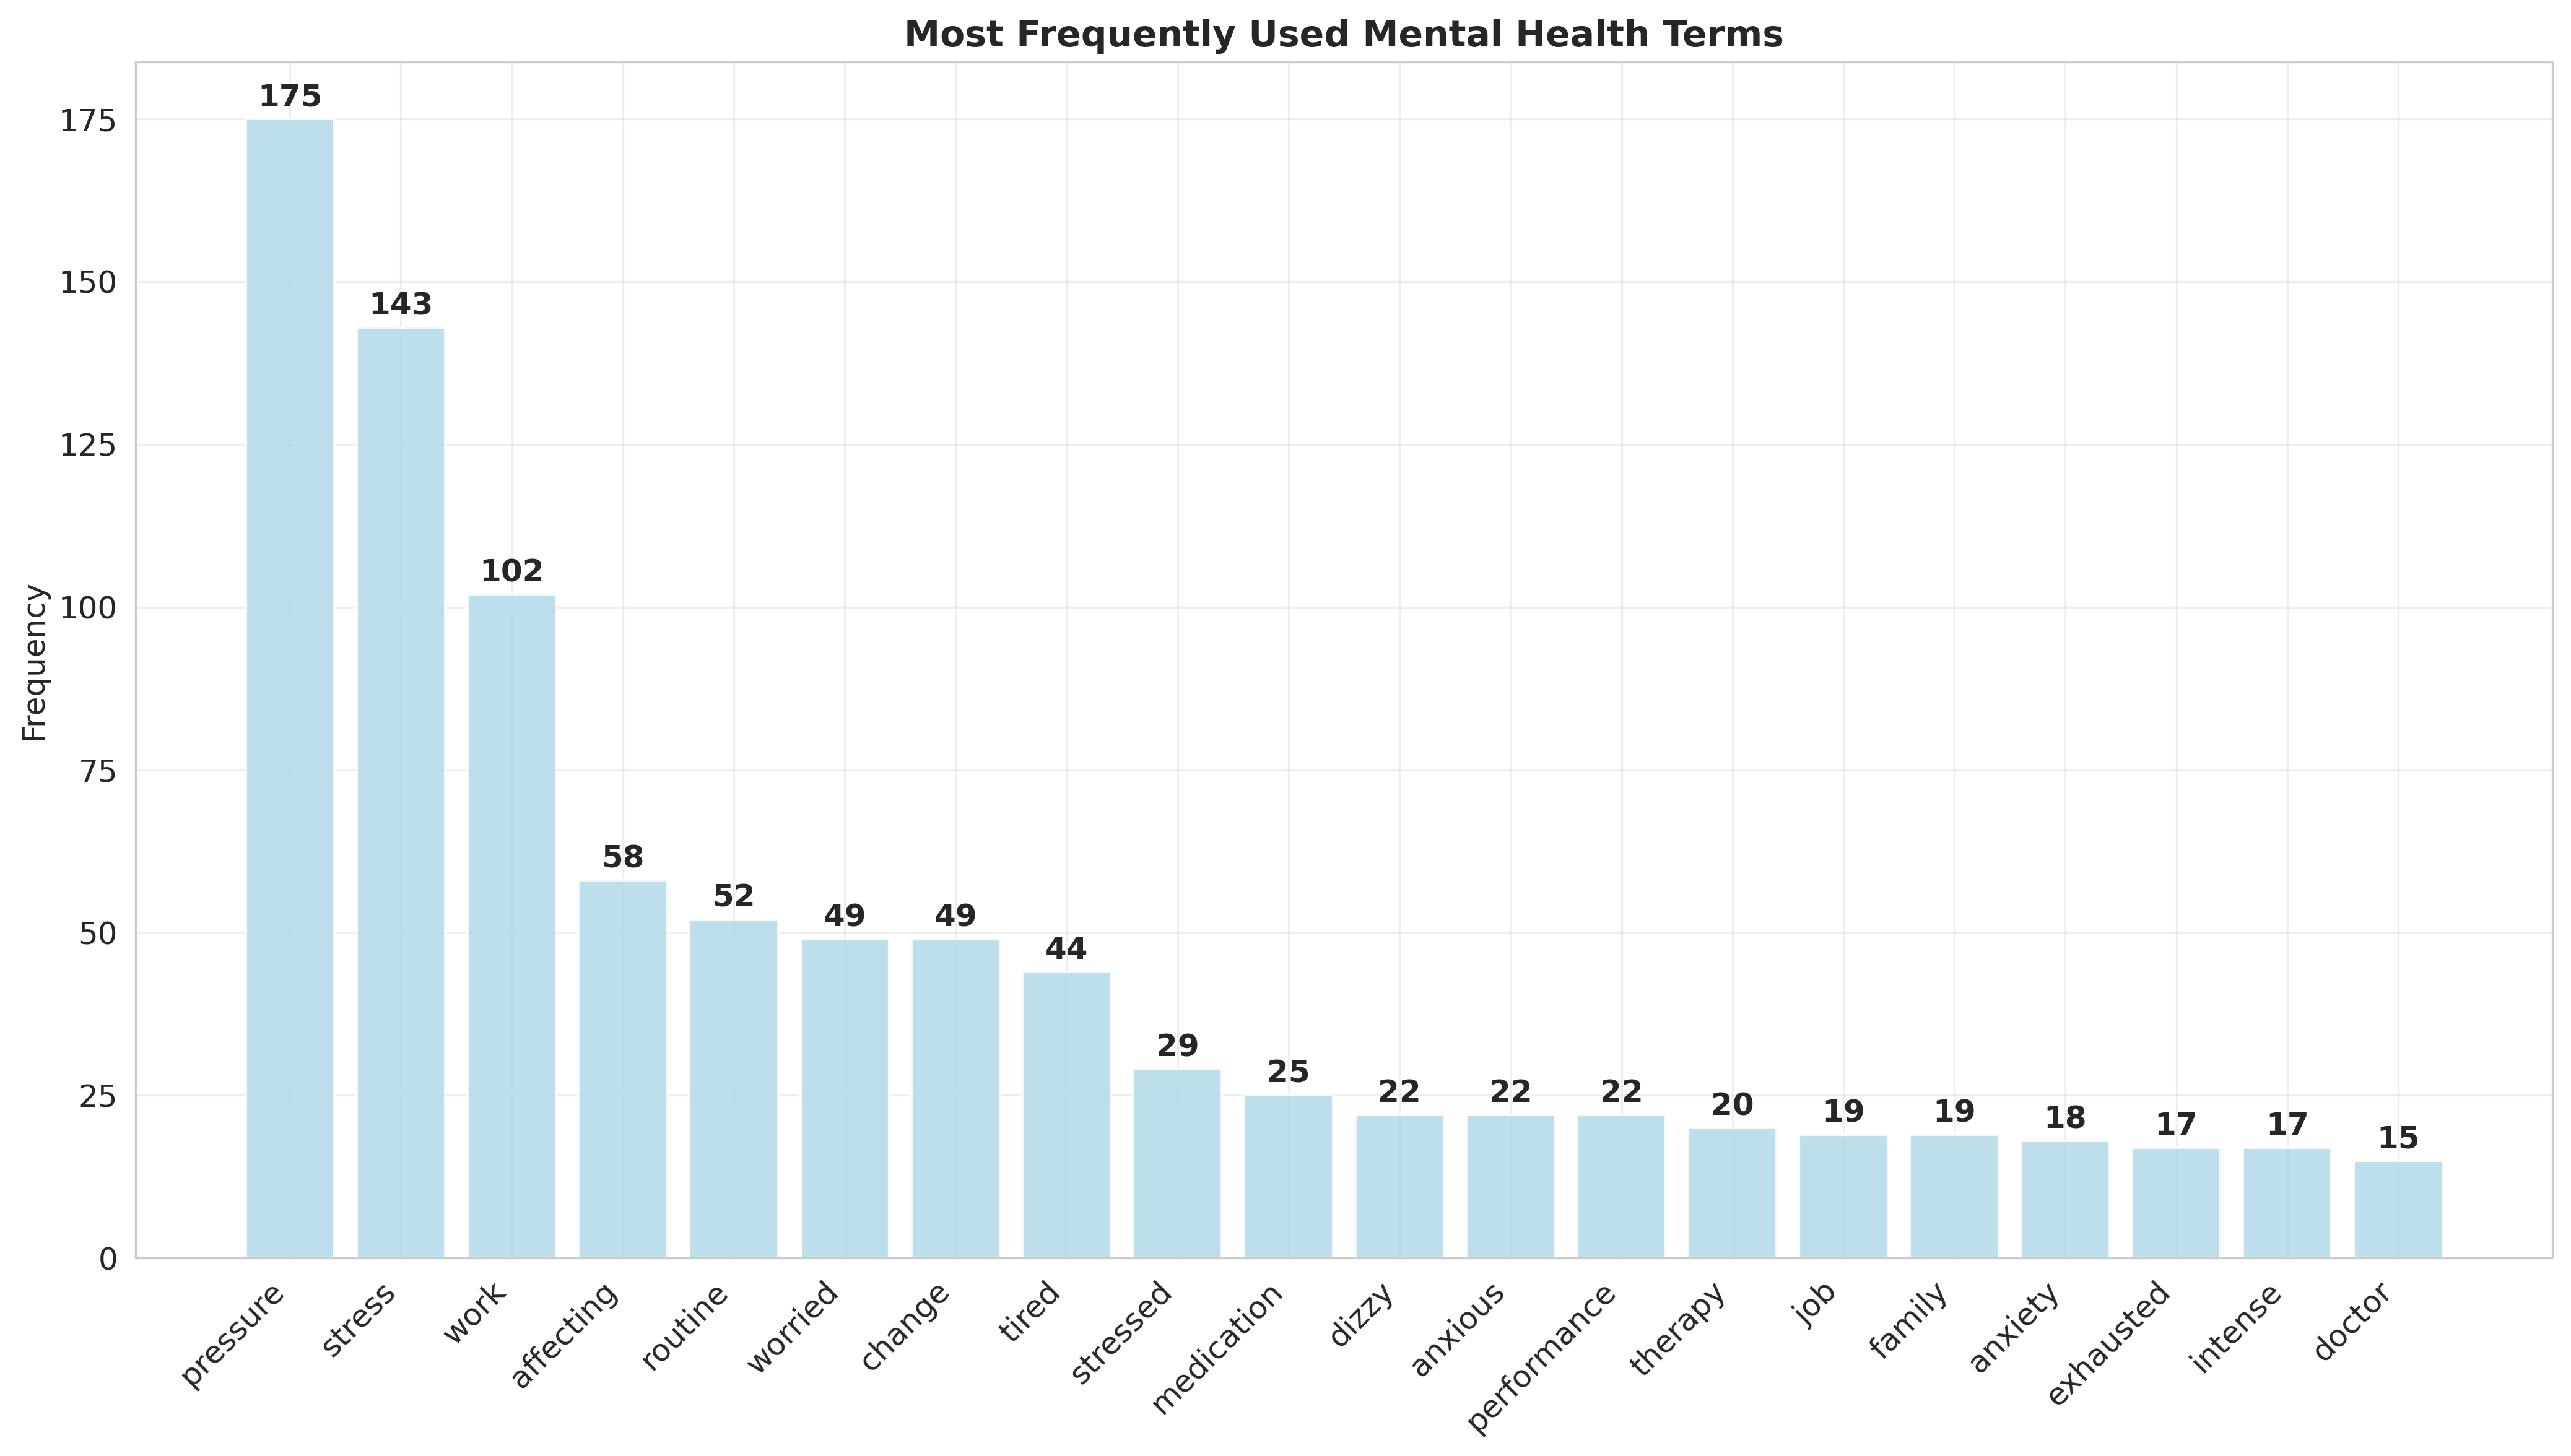

In [11]:
# Cell 7b: Most Common Mental Health Terms
plt.figure(figsize=(14, 8))
if term_frequency:
    top_terms = Counter(term_frequency).most_common(20)
    
    if top_terms:
        terms, counts = zip(*top_terms)
        bars = plt.bar(range(len(terms)), counts, color='lightblue', alpha=0.8)
        plt.xticks(range(len(terms)), terms, rotation=45, ha='right')
        plt.title('Most Frequently Used Mental Health Terms', fontweight='bold', fontsize=14)
        plt.ylabel('Frequency')
        plt.grid(True, alpha=0.3)
        
        # Add value labels
        for i, (bar, count) in enumerate(zip(bars, counts)):
            plt.text(i, count + 1, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

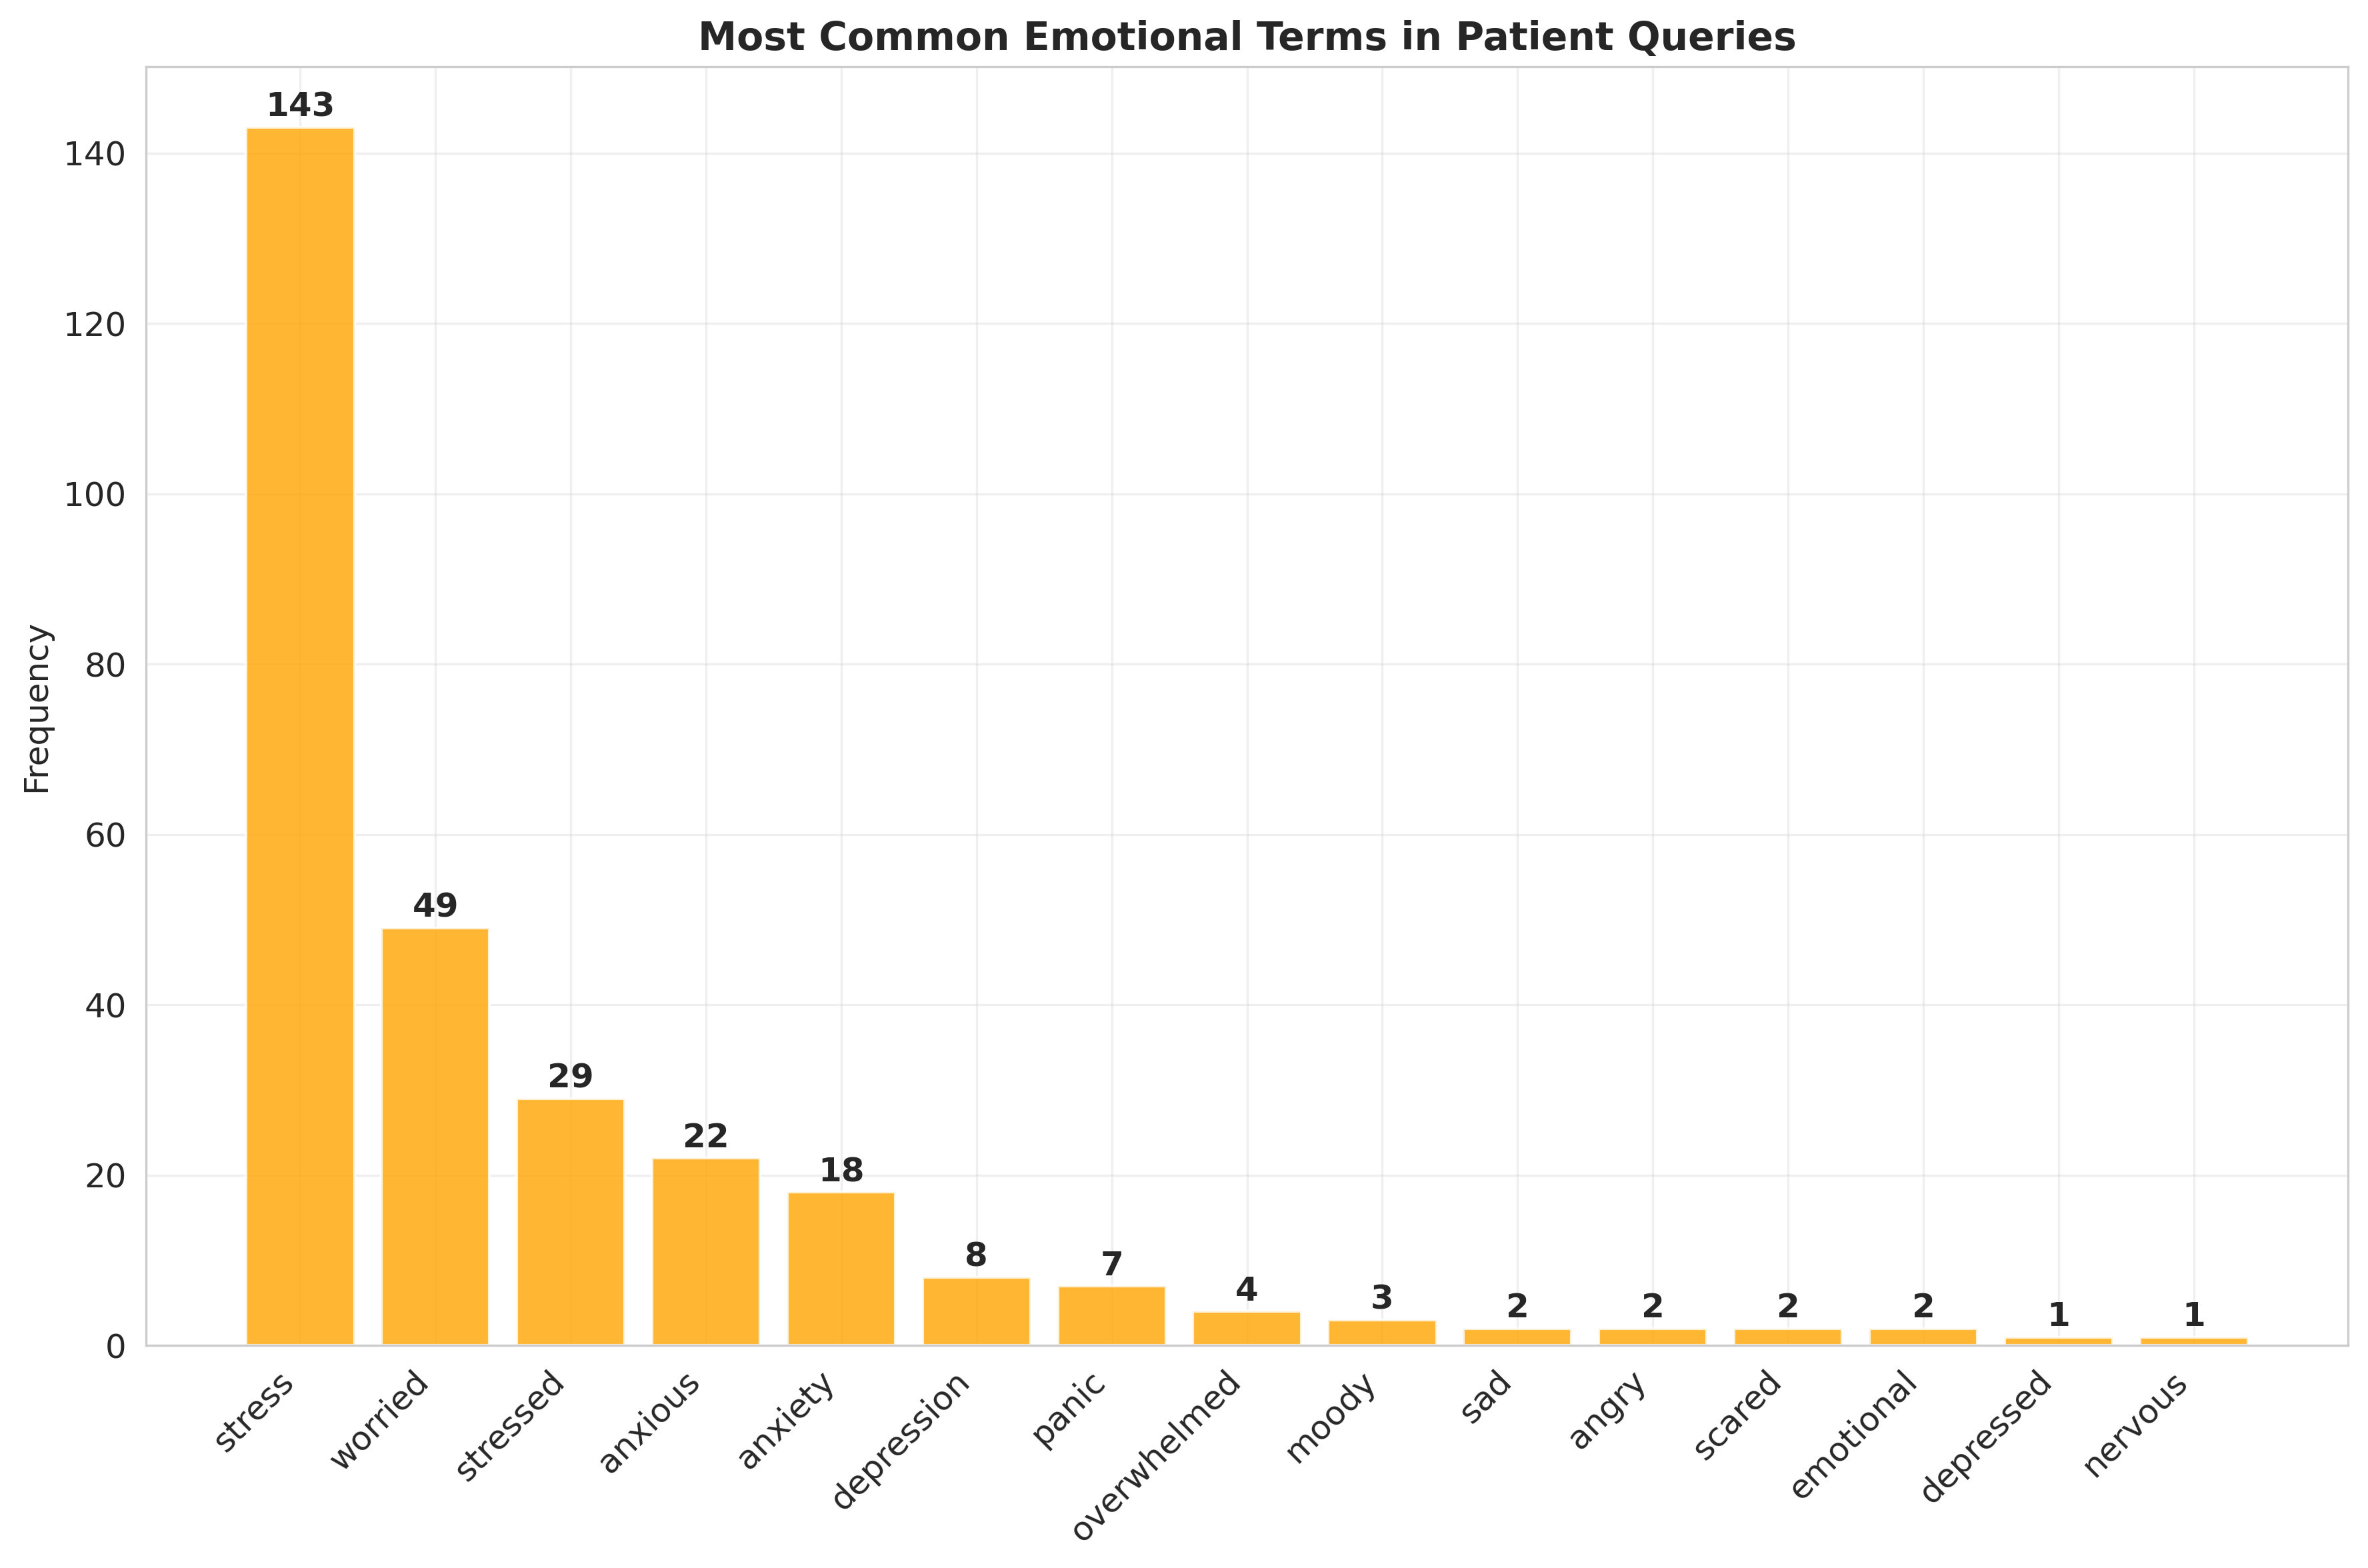

In [12]:
# Cell 7c: Emotional Terms Usage
plt.figure(figsize=(12, 8))
emotion_terms = []
for category in ['emotions']:
    if category in mental_health_vocabulary:
        for term in mental_health_vocabulary[category]:
            if term in term_frequency:
                emotion_terms.append((term, term_frequency[term]))

if emotion_terms:
    emotion_terms.sort(key=lambda x: x[1], reverse=True)
    top_emotions = emotion_terms[:15]
    
    if top_emotions:
        emotion_labels, emotion_counts = zip(*top_emotions)
        bars = plt.bar(range(len(emotion_labels)), emotion_counts, color='orange', alpha=0.8)
        plt.xticks(range(len(emotion_labels)), emotion_labels, rotation=45, ha='right')
        plt.title('Most Common Emotional Terms in Patient Queries', fontweight='bold', fontsize=14)
        plt.ylabel('Frequency')
        plt.grid(True, alpha=0.3)
        
        # Add value labels
        for i, (bar, count) in enumerate(zip(bars, emotion_counts)):
            plt.text(i, count + 0.5, str(count), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

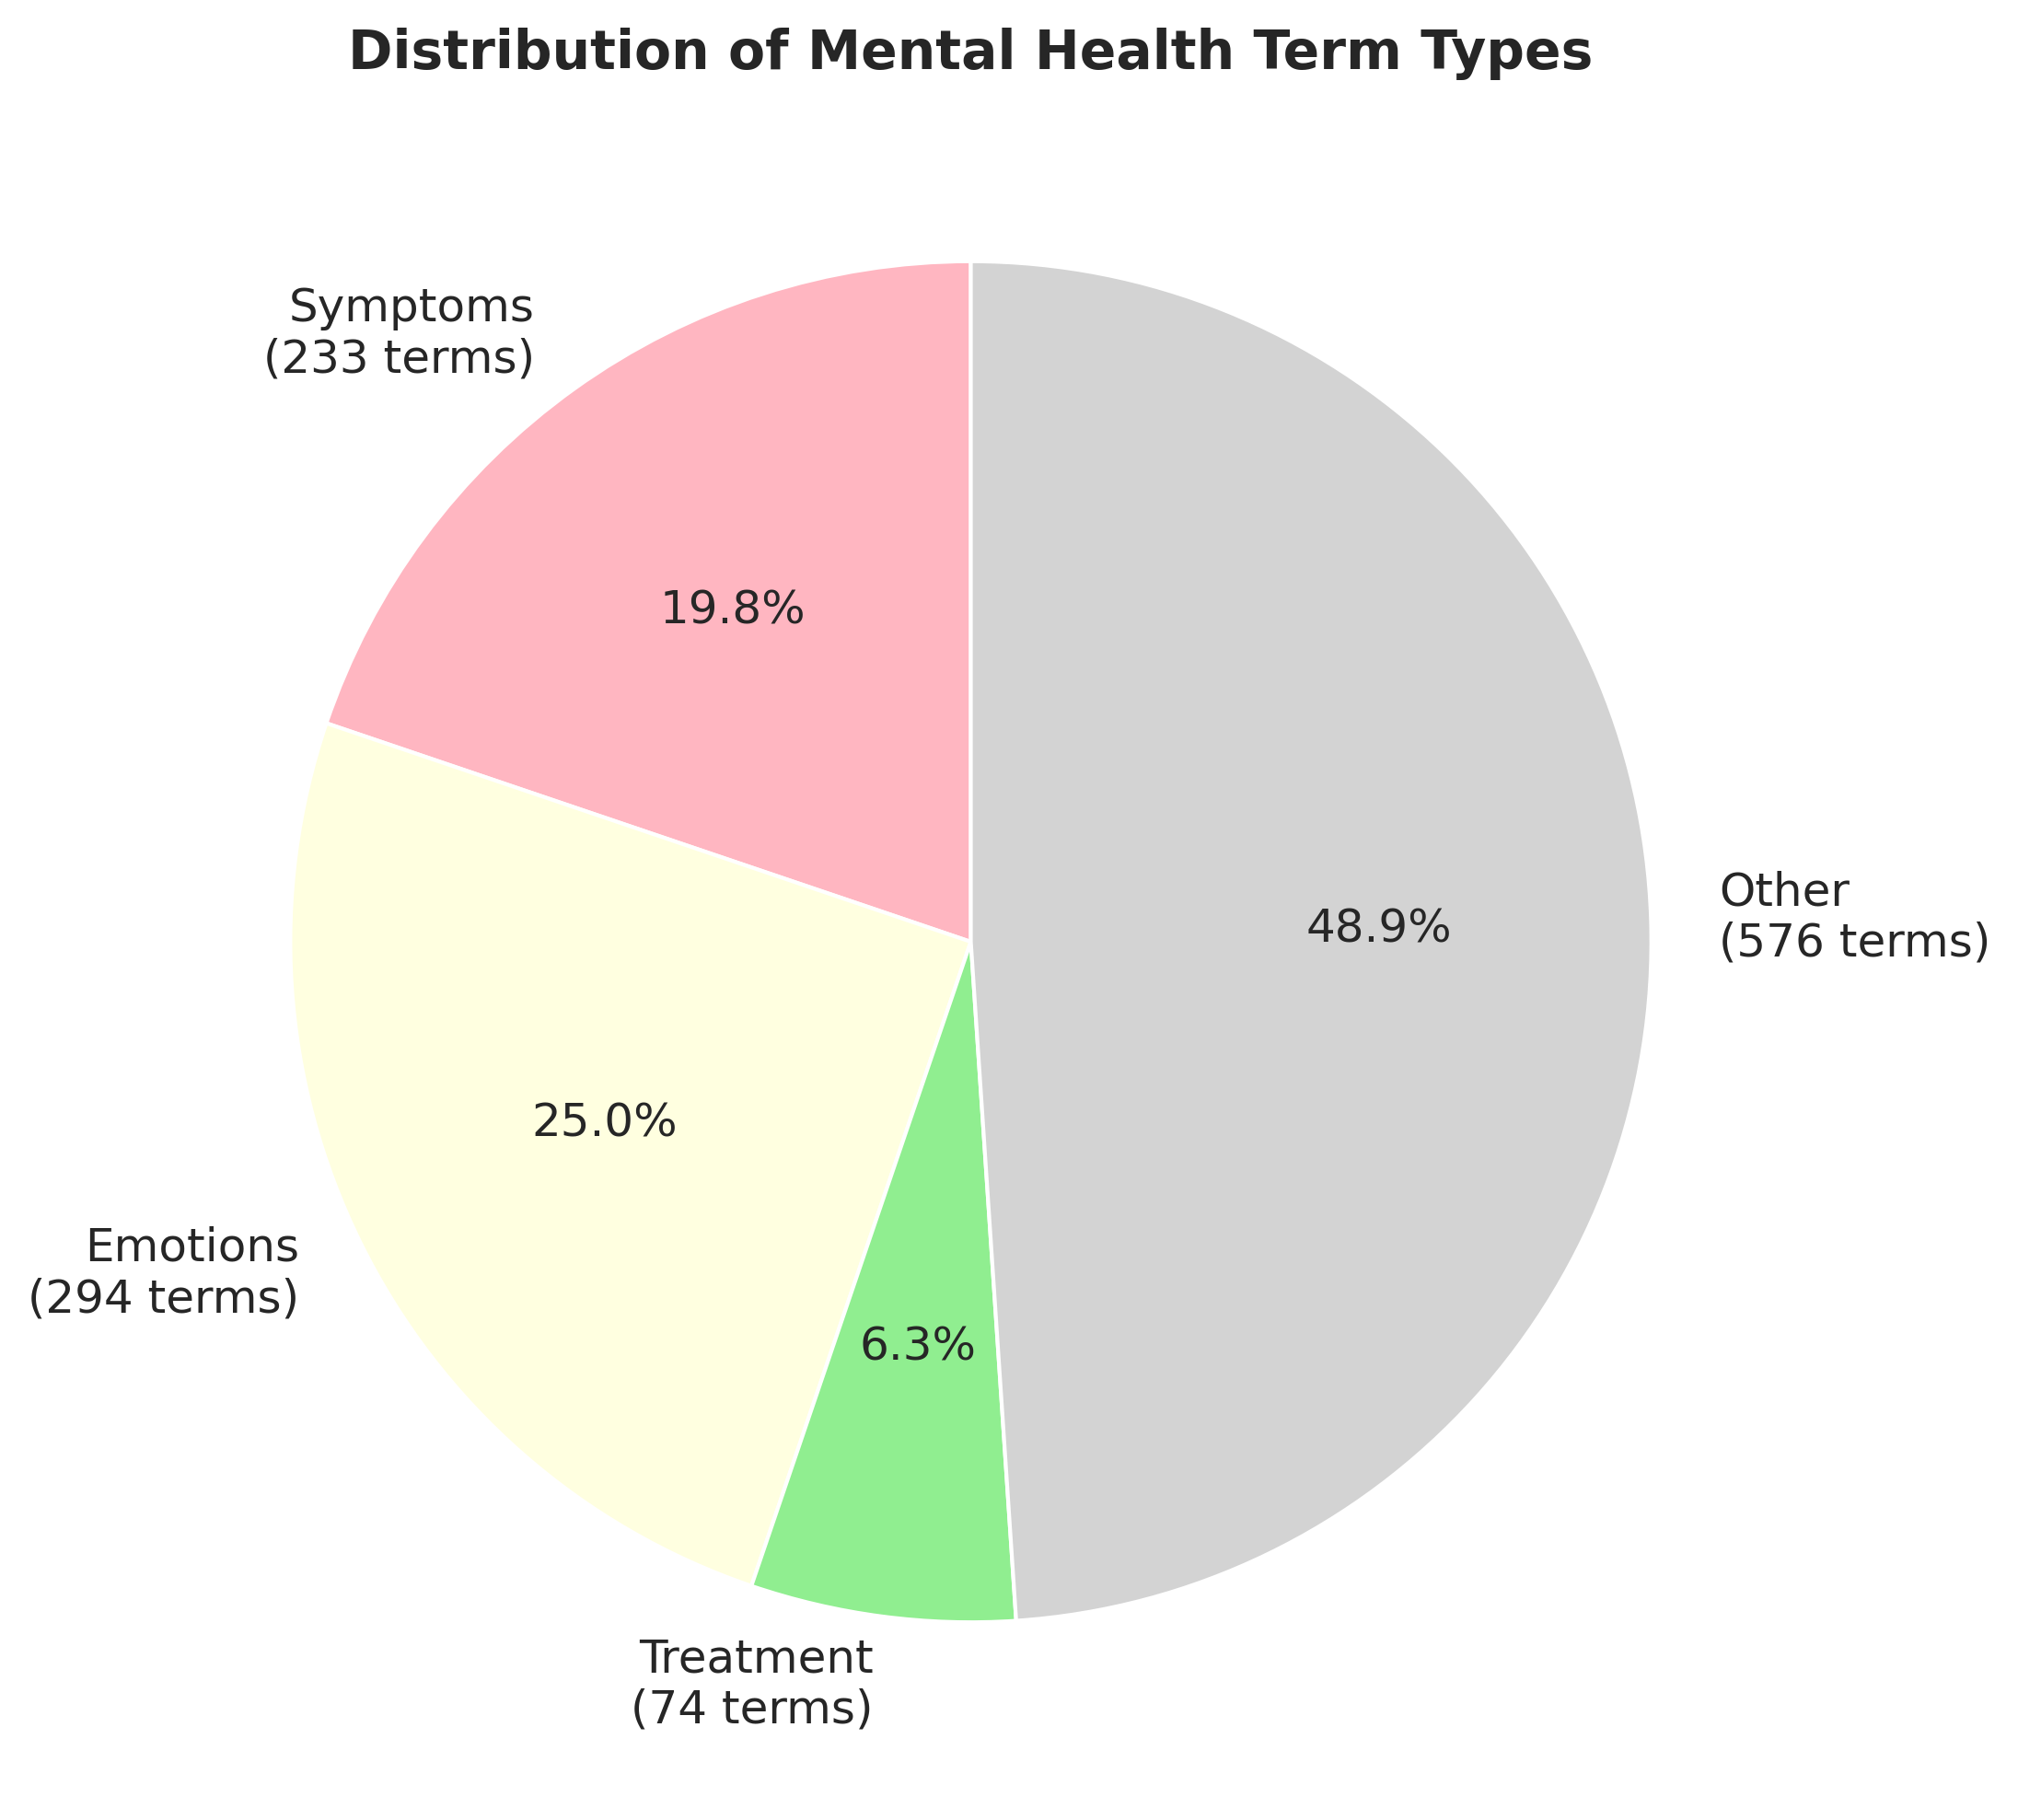

In [13]:
# Cell 7d: Symptoms vs Treatment vs Emotions Distribution
plt.figure(figsize=(10, 8))
symptom_categories = ['symptoms_physical', 'symptoms_cognitive', 'symptoms_behavioral']
treatment_categories = ['treatment_terms']

symptom_count = sum(category_frequency.get(cat, 0) for cat in symptom_categories)
treatment_count = sum(category_frequency.get(cat, 0) for cat in treatment_categories)
emotion_count = category_frequency.get('emotions', 0)
other_count = sum(category_frequency.values()) - symptom_count - treatment_count - emotion_count

categories = ['Symptoms', 'Emotions', 'Treatment', 'Other']
counts = [symptom_count, emotion_count, treatment_count, other_count]

wedges, texts, autotexts = plt.pie(counts, labels=categories, autopct='%1.1f%%', 
                                   startangle=90, colors=['lightpink', 'lightyellow', 'lightgreen', 'lightgray'])
plt.title('Distribution of Mental Health Term Types', fontweight='bold', fontsize=14)

# Add count in labels
for i, (label, count) in enumerate(zip(categories, counts)):
    texts[i].set_text(f'{label}\n({count} terms)')

plt.show()

/tmp/ipykernel_473324/350836319.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(complexity_data, labels=type_labels, patch_artist=True)


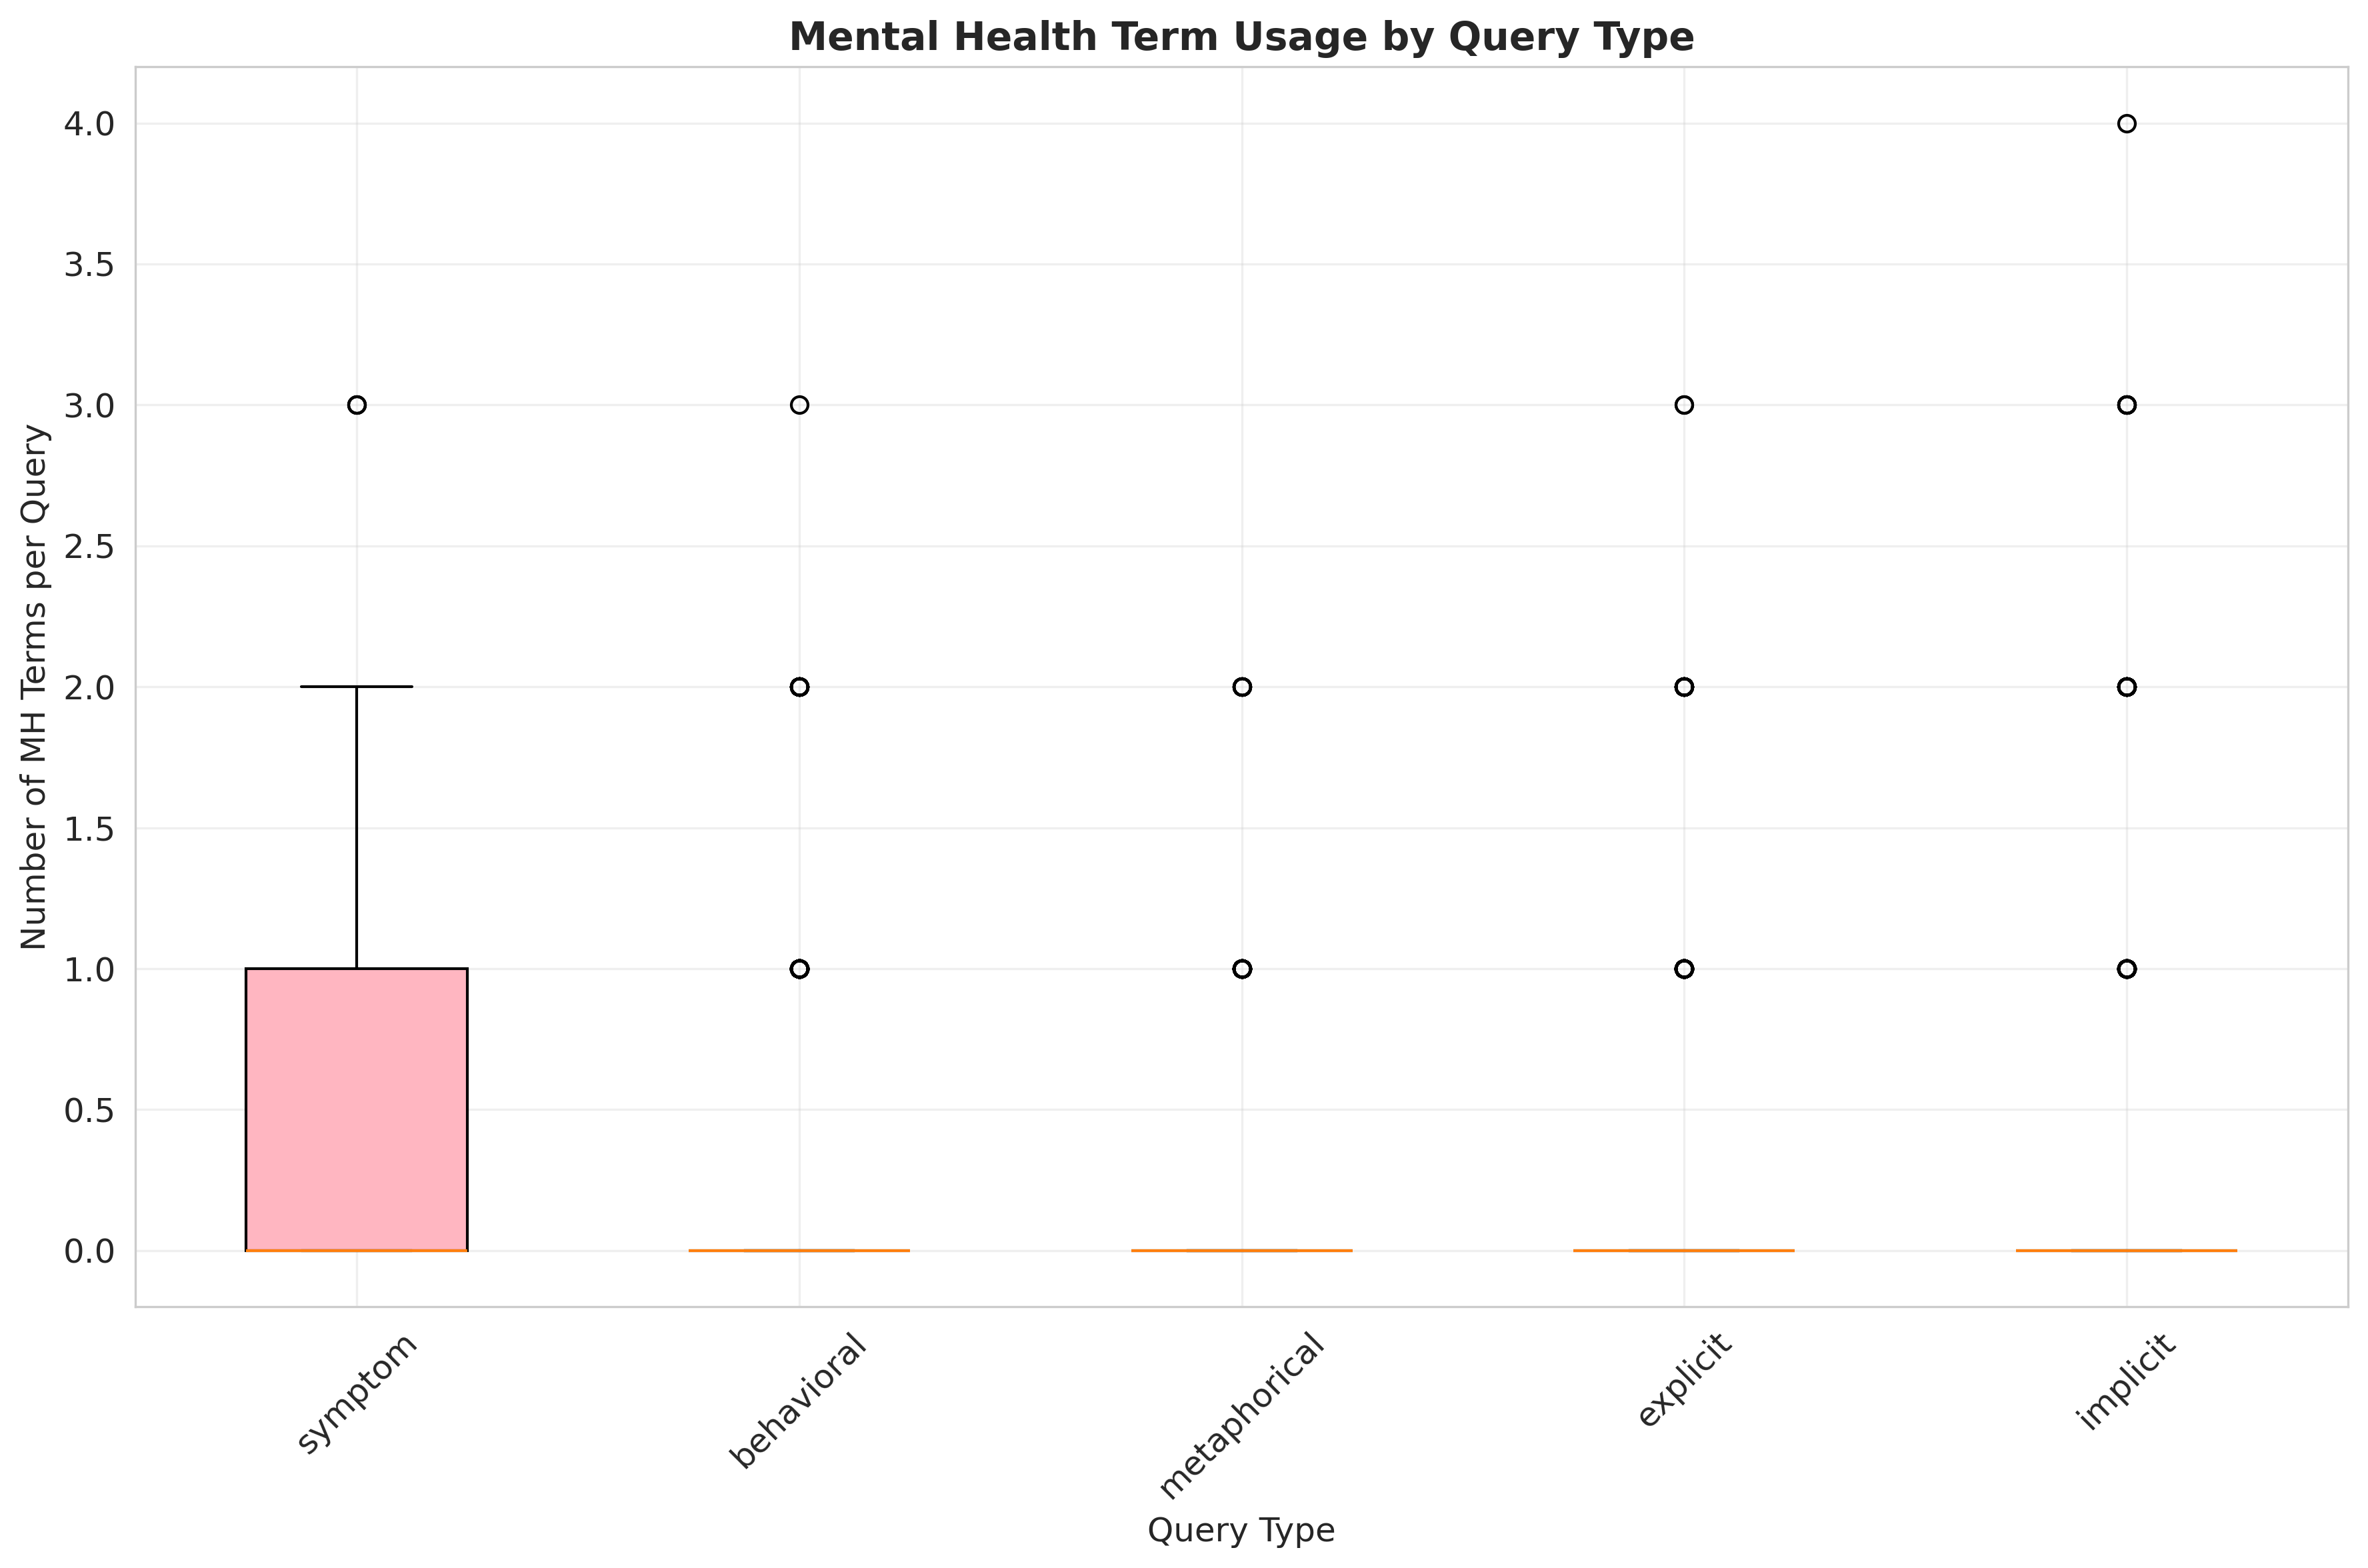

In [14]:
# Cell 7e: Mental Health Complexity by Query Type
plt.figure(figsize=(12, 8))
type_mh_complexity = defaultdict(list)
for analysis in mh_vocab_analysis:
    if analysis['type'] != 'unknown':
        type_mh_complexity[analysis['type']].append(analysis['total_mh_terms'])

if type_mh_complexity:
    type_labels = list(type_mh_complexity.keys())
    complexity_data = [type_mh_complexity[t] for t in type_labels]
    
    bp = plt.boxplot(complexity_data, labels=type_labels, patch_artist=True)
    colors = ['lightpink', 'lightblue', 'lightgreen', 'lightyellow', 'lightgray']
    for patch, color in zip(bp['boxes'], colors[:len(bp['boxes'])]):
        patch.set_facecolor(color)
    
    plt.title('Mental Health Term Usage by Query Type', fontweight='bold', fontsize=14)
    plt.xlabel('Query Type')
    plt.ylabel('Number of MH Terms per Query')
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

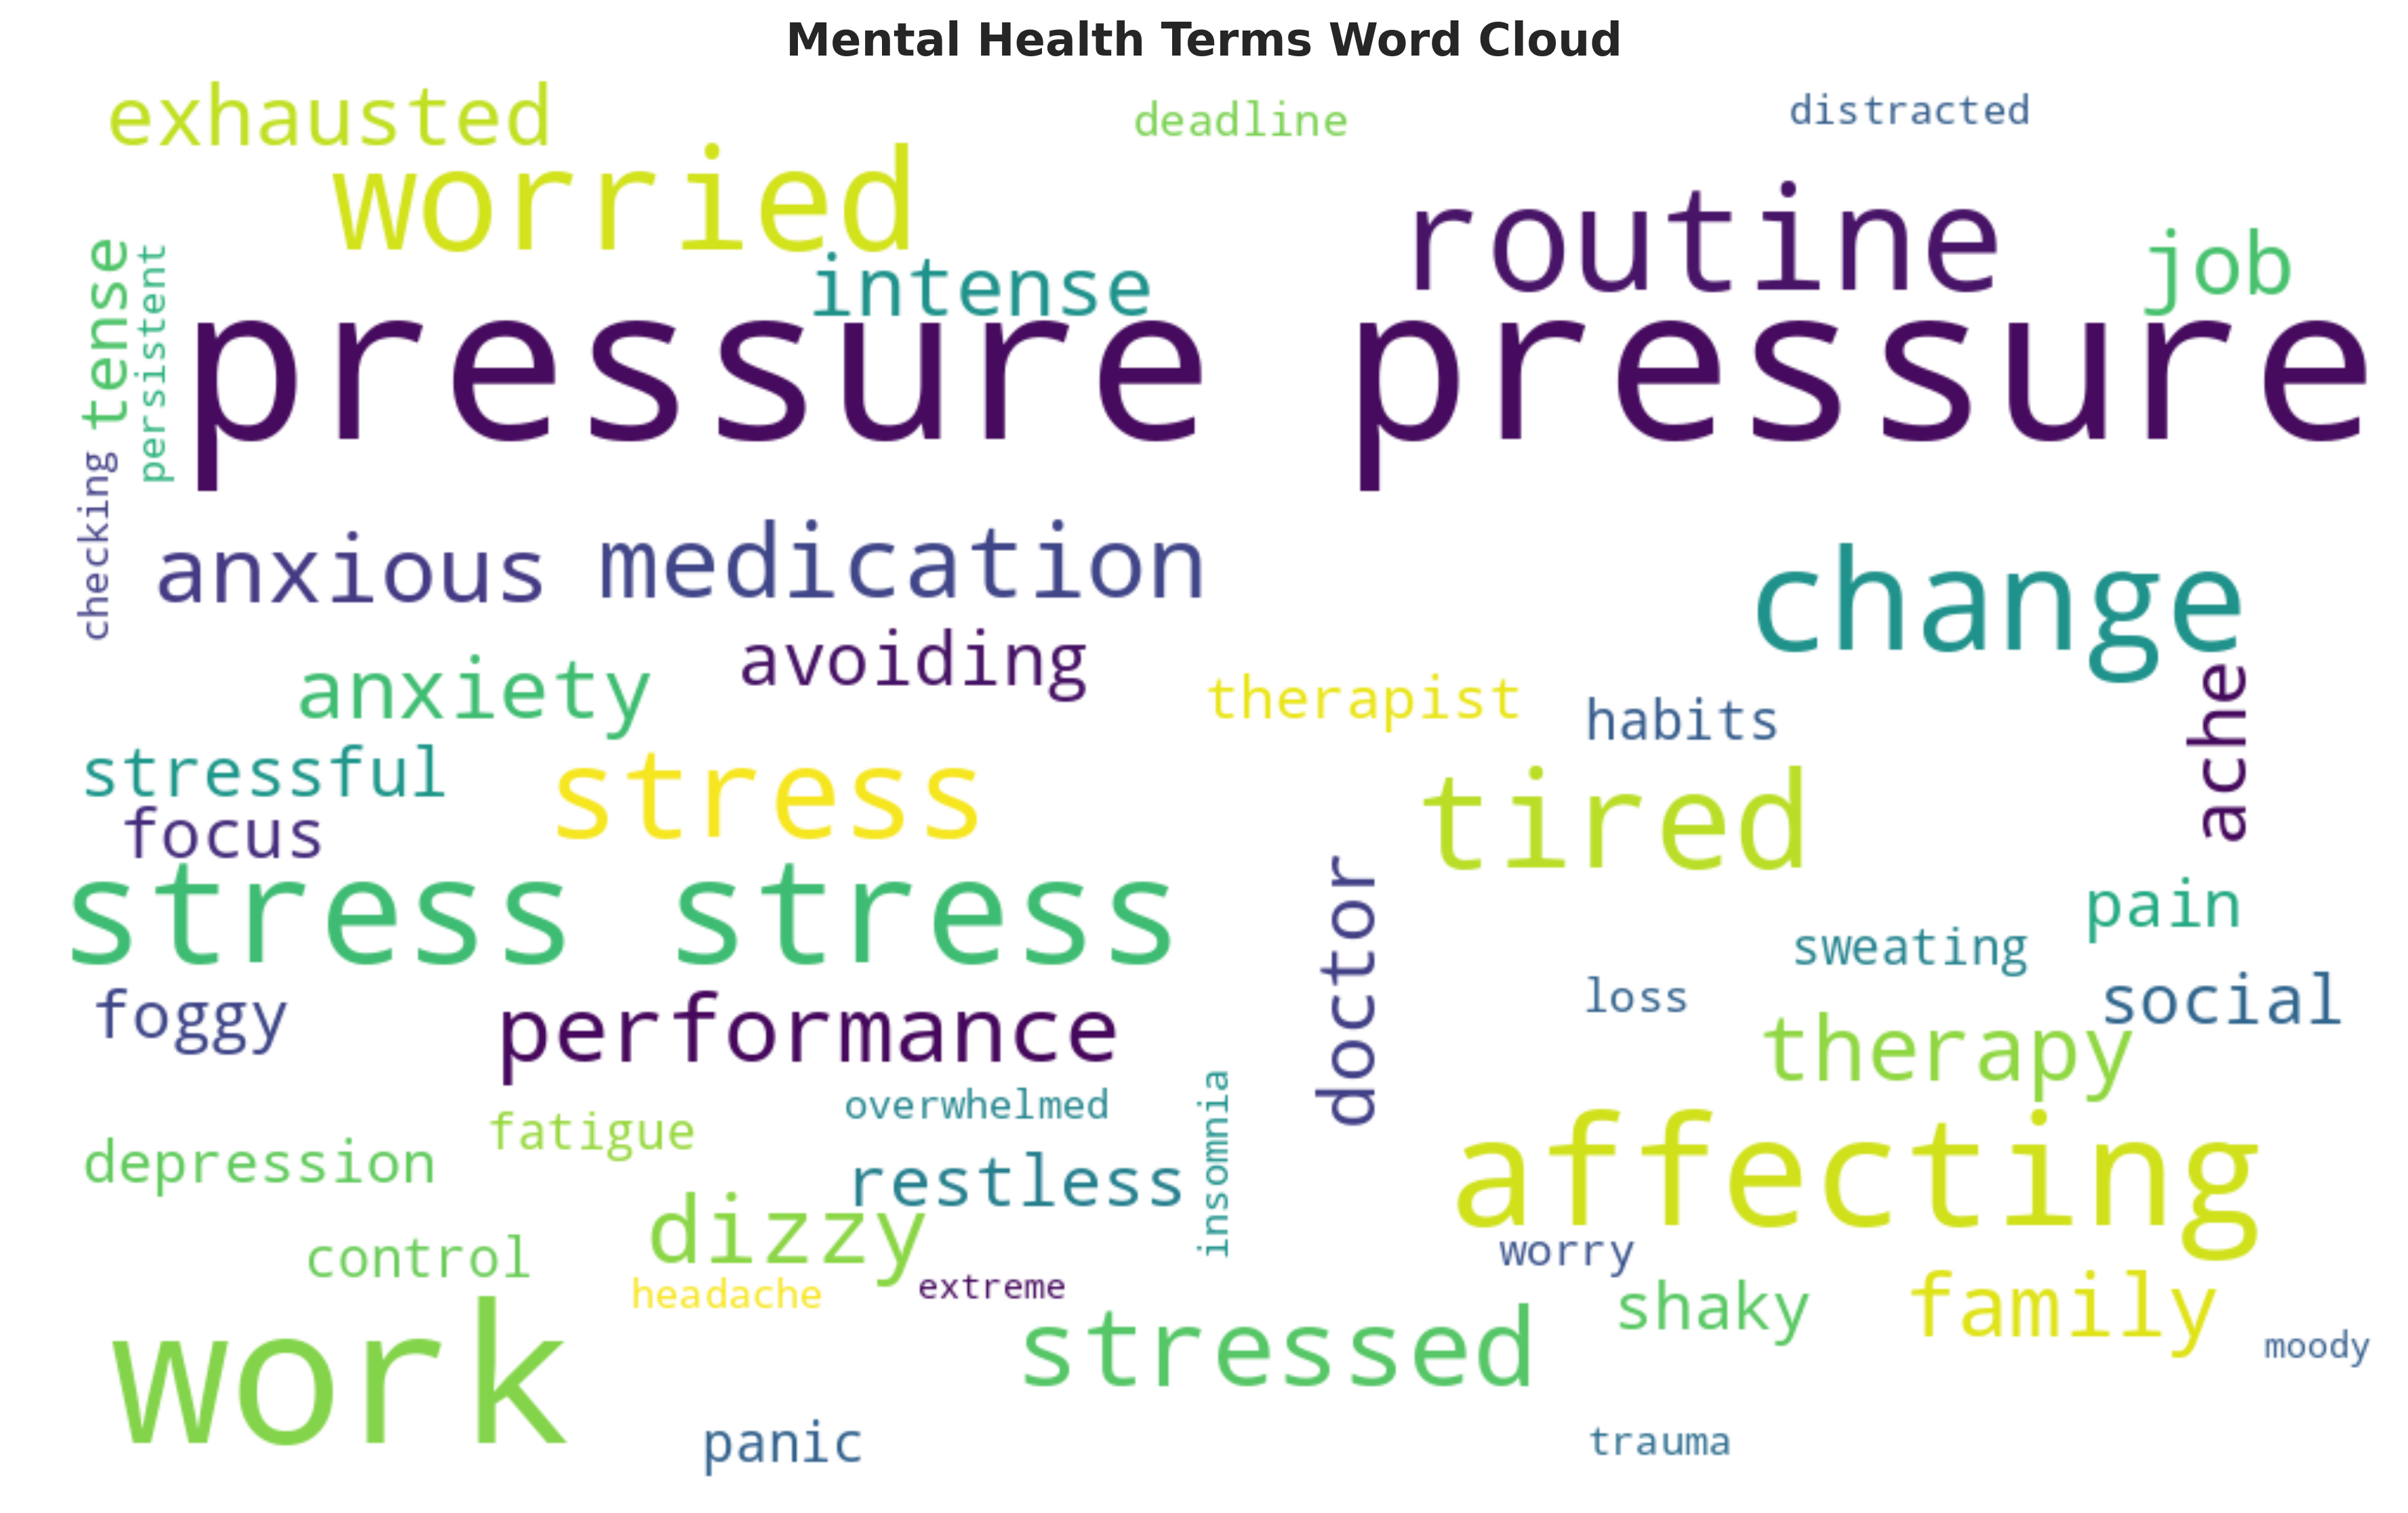


📊 MENTAL HEALTH VOCABULARY SUMMARY:
---------------------------------------------
Total queries analyzed: 5099
Queries with mental health terms: 1039 (20.4%)

📈 Top Categories:
--------------------
  Emotions: 294 occurrences
  Daily Impact: 286 occurrences
  Triggers: 251 occurrences
  Symptoms Physical: 166 occurrences
  Treatment Terms: 74 occurrences

🔤 Top Terms:
---------------
  'pressure': 175 times
  'stress': 143 times
  'work': 102 times
  'affecting': 58 times
  'routine': 52 times


In [15]:
# Cell 7f: Word Cloud of Mental Health Terms
plt.figure(figsize=(12, 8))
if all_mh_terms:
    # Create frequency text for word cloud
    wordcloud_text = ' '.join(all_mh_terms)
    
    wordcloud = WordCloud(width=1000, height=600, background_color='white',
                         colormap='viridis', max_words=50, relative_scaling=0.5).generate(wordcloud_text)
    
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title('Mental Health Terms Word Cloud', fontweight='bold', fontsize=16)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\n📊 MENTAL HEALTH VOCABULARY SUMMARY:")
print("-" * 45)
print(f"Total queries analyzed: {len(mh_vocab_analysis)}")

queries_with_mh_terms = len([a for a in mh_vocab_analysis if a['mh_terms']])
print(f"Queries with mental health terms: {queries_with_mh_terms} ({queries_with_mh_terms/len(mh_vocab_analysis)*100:.1f}%)")

print(f"\n📈 Top Categories:")
print("-" * 20)
for category, count in sorted(category_frequency.items(), key=lambda x: x[1], reverse=True)[:5]:
    if count > 0:
        clean_name = category.replace('_', ' ').title()
        print(f"  {clean_name}: {count} occurrences")

print(f"\n🔤 Top Terms:")
print("-" * 15)
top_terms = Counter(term_frequency).most_common(5)
for term, count in top_terms:
    print(f"  '{term}': {count} times")